# Midterm Exam (UTS) in Data Science Graphs: Neo4j Python Driver and Recommender Systems

**Bachelor’s Program in Data Science, State University of Surabaya (Universitas Negeri Surabaya) | Odd Semester 2026/2027 | Individual Assignment**

## Workflow

```
events.csv (RetailRocket)
| 2.1.1-2  Timestamp filtering -> train_events.csv (P1) and test_events.csv (P2)
v
Neo4j  <-- Batch import of training fold: (:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(:Item)
| 2.1.3    Subgraph composition (Cypher via Python API)
| 2.1.4-5  Vector Space Model: Users (rows) and Items (columns), NetworkX visualization
| 2.1.6    Bipartite projection: user-user vs. item-item (for efficiency and effectiveness)
| 2.1.7    Similarity calculation (Python) -> written back as :SIMILAR_TO relationships
| 2.1.8    Graph state: before vs. after adding similarity relationships
v
2.2  KNN for a randomly selected user (k=5, 3 recommended items) -> Hit@5 and NDCG@5 evaluated against the test fold
```

## Output Files

| File | Content |
|---|---|
| `data/processed/train_events.csv`, `test_events.csv` | Results of timestamp filtering (Task 2.1.2) |
| `outputs/tables/*.csv` | All result tables (composition, VSM statistics, projection comparisons, kNN, recommendations, metrics) |
| `outputs/figures/*.png` | all images (networkx, degree distribution, before/after) |
| `outputs/run_config.json` | run parameters (time period, seed, k) for reproducibility |

## Configuration and Library Imports

- **Credentials** are read from environment variables (`NEO4J_URI`, `NEO4J_USER`, `NEO4J_PASSWORD`).
- **Time periods** (`TRAIN_*`, `TEST_*`): The assignment requires that the chosen combination of periods **must be unique** (i.e., different from those of other students in the class).
- The **SEED** governs all stochastic processes (such as user selection and the sampling of evaluation data). Using the same seed ensures identical results across different runs.
- **Event weights** `view=1`, `addtocart=2`, and `transaction=3` reflect the strength of the interest signal within the implicit feedback.

In [1]:
import os, sys, json, time, math, inspect, warnings
from pathlib import Path
from dotenv import load_dotenv

import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

NAMA = "Dimas Rafi Izzulhaq"
NIM = "24031554084"

load_dotenv()
NEO4J_URI = os.getenv("NEO4J_URI", "neo4j://localhost:7687")
NEO4J_USER = os.getenv("NEO4J_USER", "neo4j")
NEO4J_PASS = os.getenv("NEO4J_PASSWORD")
NEO4J_DB = os.getenv("NEO4J_DATABASE", "neo4j")

ROOT = Path.cwd()
RAW_DIR, PROC_DIR = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG_DIR, TAB_DIR = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
for d in (RAW_DIR, PROC_DIR, FIG_DIR, TAB_DIR):
    d.mkdir(parents=True, exist_ok=True)
EVENTS_RAW = RAW_DIR / "events.csv"
TRAIN_CSV, TEST_CSV = PROC_DIR / "train_events.csv", PROC_DIR / "test_events.csv"

TRAIN_START, TRAIN_END = "2015-07-23", "2015-07-31"   # P1: fold training
TEST_START, TEST_END = "2015-08-01", "2015-08-09"     # P2: fold testing

SEED = 4084
K_NEIGHBORS = 5
N_ADS = 3
TOP_N = 5
MIN_SUPPORT = 2
EVAL_SAMPLE = 5000
PROJECTION = "auto"
IMPORT_BATCH_SIZE = 5000

EVENT_WEIGHT = {"view": 1, "addtocart": 2, "transaction": 3}
REL_TYPE = {"view": "VIEWED", "addtocart": "ADDED_TO_CART", "transaction": "BOUGHT"}
REL_PATTERN = "|".join(REL_TYPE.values())
WEIGHT_CASE = "CASE type(r) " + " ".join(f"WHEN '{REL_TYPE[e]}' THEN {w}" for e, w in EVENT_WEIGHT.items()) + " ELSE 1 END"

print(f"{NAMA} ({NIM})")
print(f"Train: {TRAIN_START} .. {TRAIN_END} | Test: {TEST_START} .. {TEST_END} | seed={SEED}")

Dimas Rafi Izzulhaq (24031554084)
Train: 2015-07-23 .. 2015-07-31 | Test: 2015-08-01 .. 2015-08-09 | seed=4084


c:\Users\LENOVO\Documents\KULLYEAH\Semester 5\Graf Sains Data\UTS\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# 1. Preliminary Task

## 1.1 Preparation and Environment Setup

A virtual environment (`venv` or `uv`) isolates project dependencies, preventing conflicts with other projects.

**Important note regarding the `requirements.txt` file provided in the assignment:** 

The file contains `neo4j==4.2.1` (along with `neo4j>=4.0,<4.3`). The 4.x version **does not include** the `driver.execute_query(...)` method used in tutorial 1.2 (this API was introduced in driver version 5.5). Furthermore, `nose==1.3.7` is incompatible with Python 3.10 and later versions. Consequently, an updated `requirements.txt` file has been provided (including `neo4j>=5.20,<6`, as well as `pandas`, `scipy`, `networkx`, `matplotlib`, and `tqdm`). The following cell verifies the environment.

In [2]:
import importlib.metadata as imd

print("Python :", sys.version.split()[0])
for pkg in ["neo4j", "pandas", "numpy", "scipy", "networkx", "matplotlib", "tqdm"]:
    print(f"{pkg:11s}:", imd.version(pkg))

assert int(imd.version("neo4j").split(".")[0]) >= 5, (
    "The Neo4j driver < 5 does not have execute_query(). Run: pip install 'neo4j>=5.20,<6'")

Python : 3.12.0
neo4j      : 5.28.8
pandas     : 3.0.6
numpy      : 2.5.4
scipy      : 1.18.1
networkx   : 3.7
matplotlib : 3.11.2
tqdm       : 4.70.1


## 1.2 Learning to Use the Neo4j Driver *(Neo4j)*

**Concepts covered in this tutorial:**

- `GraphDatabase.driver(URI, auth=...)` creates a *driver*: a long-lived, thread-safe object that manages a connection pool. Only one driver is needed per application; it should be closed using `close()` or a `with` statement.
- `driver.execute_query(query, ..., database_=..., routing_=...)` is a high-level API that opens a session, executes a single *managed transaction* (which automatically retries in the event of transient failures), and then closes the session. Arguments ending with an underscore (`_`) are configuration settings, while the others (e.g., `name=...`) are **query parameters**.
- `routing_=RoutingControl.READ` informs the cluster that the query is read-only, allowing it to be served by a replica. While this has no effect on a single-instance setup, it is considered a best practice.
- **Parameterized queries** (using `$name`) must be used instead of string formatting; this prevents Cypher injection and enables query plan caching.
- `MERGE` functions as a "get-or-create" operation: it ensures that `Person` nodes are not duplicated and `KNOWS` relationships are not created multiple times, making the operation **idempotent**.

In [3]:
from neo4j import GraphDatabase, RoutingControl

driver = GraphDatabase.driver(NEO4J_URI, auth=(NEO4J_USER, NEO4J_PASS))
driver.verify_connectivity()
print("Terhubung ke", NEO4J_URI, "| database:", NEO4J_DB)

Terhubung ke neo4j://localhost:7687 | database: neo4j


In [4]:
def cypher_df(query, params=None, database=None):
    return driver.execute_query(
        query, parameters_=params or {}, database_=database or NEO4J_DB,
        routing_=RoutingControl.READ, result_transformer_=lambda res: res.to_df())

def add_friend(driver, name, friend_name):
    driver.execute_query(
        "MERGE (a:Person {name: $name}) "
        "MERGE (friend:Person {name: $friend_name}) "
        "MERGE (a)-[:KNOWS]->(friend)",
        name=name, friend_name=friend_name, database_=NEO4J_DB,
    )

def print_friends(driver, name):
    records, _, _ = driver.execute_query(
        "MATCH (a:Person)-[:KNOWS]->(friend) WHERE a.name = $name "
        "RETURN friend.name ORDER BY friend.name",
        name=name, database_=NEO4J_DB, routing_=RoutingControl.READ,
    )
    for record in records:
        print(record["friend.name"])

add_friend(driver, "Arthur", "Guinevere")
add_friend(driver, "Arthur", "Lancelot")
add_friend(driver, "Arthur", "Merlin")
print_friends(driver, "Arthur")

Guinevere
Lancelot
Merlin


### Introductory Questions (Checkpoint)

**1. What is the name of the database used in this tutorial?**

The database is named **`neo4j`**, which is the default user database in every Neo4j instance. This is indicated by the argument `database_="neo4j"`. Additionally, there is always a system database called `system` (containing metadata, users, and access rights). The cell below demonstrates this programmatically.

**2. Other ways to access different databases within a single instance:**

- *Python API:* `driver.session(database="db_name")` or `execute_query(..., database_="db_name")`.
- *Administrative DDL* (executed on the `system` database): `SHOW DATABASES`, `CREATE DATABASE db_name IF NOT EXISTS`, `START/STOP DATABASE db_name`, `DROP DATABASE db_name`.
- *Cross-database DML:* Using the `USE db_name` clause at the beginning of a query (e.g., `USE db_name MATCH (n) RETURN n LIMIT 5`) or the `:use db_name` command in the Neo4j Browser.
- *Edition limitations:* The Community Edition only allows for **one** user database (`neo4j`) in addition to the `system` database. Full multi-database support is available in the paid Enterprise edition or AuraDB.

**3. The type of friendship graph created:**

It is a **directed**, **homogeneous/unipartite** graph (consisting of a single node type, `Person`, and a single relationship type, `KNOWS`). It is **unweighted** and **simple** (containing no self-loops or multiple relationships between the same nodes, thanks to the use of `MERGE`). It follows the **property graph** model, where nodes possess a `name` property. The topological structure is an **out-star** centered on Arthur: Arthur has an out-degree of 3, while each friend has an in-degree of 1. Since there are no reciprocal relationships, the `KNOWS` relationship here is **asymmetric** (Arthur knowing Merlin does not imply that Merlin knows Arthur).

In [5]:
display(cypher_df("SHOW DATABASES YIELD name, type, access, currentStatus RETURN name, type, access, currentStatus", database="system"))

derajat = cypher_df("""
    MATCH (p:Person)
    RETURN p.name AS nama,
           COUNT { (p)-[:KNOWS]->() } AS out_degree,
           COUNT { (p)<-[:KNOWS]-() } AS in_degree
    ORDER BY nama
""")
display(derajat)

timbal_balik = cypher_df("MATCH (a:Person)-[:KNOWS]->(b:Person)-[:KNOWS]->(a) RETURN count(*) AS pasangan_timbal_balik")
self_loop = cypher_df("MATCH (a:Person)-[:KNOWS]->(a) RETURN count(*) AS self_loop")
print("Reciprocal relations:", int(timbal_balik.iloc[0, 0]), "| self-loops:", int(self_loop.iloc[0, 0]))

,name,type,access,currentStatus
0,neo4j,standard,read-write,online
1,system,system,read-write,online


,nama,out_degree,in_degree
0,Arthur,3,0
1,Guinevere,0,1
2,Lancelot,0,1
3,Merlin,0,1


Reciprocal relations: 0 | self-loops: 0


In [6]:
driver.execute_query("MATCH (p:Person) DETACH DELETE p", database_=NEO4J_DB)

EagerResult(records=[], summary=<neo4j._work.summary.ResultSummary object at 0x000002A0957CDFD0>, keys=[])

> **About *CYPHER Total Reset*.** `MATCH (n) DETACH DELETE n;` deletes the **entire** contents of a database in a single transaction (risking an out-of-memory error with large datasets and potentially damaging a *shared database*). In this notebook, the cleanup is restricted to custom-created labels (`Person`, as well as `Visitor`/`Item`), and the deletion of large volumes of data is performed using `CALL {...} IN TRANSACTIONS OF 10000 ROWS`.

## 1.3 RetailRocket Data Preparation

Data source: Roman Zykov, *Retailrocket recommender system dataset* (Kaggle). Only the `events.csv` file is used.

| Column | Meaning |
|---|---|
| `timestamp` | Time of the event, **Unix epoch in milliseconds** (not seconds; convert using `unit="ms"`) |
| `visitorid` | Unique visitor ID |
| `event` | `view`, `addtocart`, `transaction` |
| `itemid` | Unique product ID |
| `transactionid` | Transaction ID; populated only when `event == "transaction"` |

In [7]:
if not EVENTS_RAW.exists():
    raise FileNotFoundError(
        f"{EVENTS_RAW} not found")

events = pd.read_csv(
    EVENTS_RAW,
    dtype={"visitorid": "int64", "itemid": "int64", "event": "category", "transactionid": "Int64"},
)
events["datetime"] = pd.to_datetime(events["timestamp"], unit="ms", utc=True)

print(f"Row: {len(events):,} | Unique visitors: {events['visitorid'].nunique():,} | Unique items: {events['itemid'].nunique():,}")
print(f"Time range: {events['datetime'].min()} to {events['datetime'].max()}")

display(events["event"].value_counts().rename("jumlah").to_frame().assign(
    persen=lambda d: (100 * d["jumlah"] / d["jumlah"].sum()).round(2)))
display(events.head())
display(events.isna().sum().rename("jumlah_null").to_frame())

Row: 2,756,101 | Unique visitors: 1,407,580 | Unique items: 235,061
Time range: 2015-05-03 03:00:04.384000+00:00 to 2015-09-18 02:59:47.788000+00:00


,jumlah,persen
event,,
view,2664312,96.67
addtocart,69332,2.52
transaction,22457,0.81


,timestamp,visitorid,event,itemid,transactionid,datetime
0,1433221332117,257597,view,355908,<NA>,2015-06-02 05:02:12.117000+00:00
1,1433224214164,992329,view,248676,<NA>,2015-06-02 05:50:14.164000+00:00
2,1433221999827,111016,view,318965,<NA>,2015-06-02 05:13:19.827000+00:00
3,1433221955914,483717,view,253185,<NA>,2015-06-02 05:12:35.914000+00:00
4,1433221337106,951259,view,367447,<NA>,2015-06-02 05:02:17.106000+00:00


,jumlah_null
timestamp,0
visitorid,0
event,0
itemid,0
transactionid,2733644
datetime,0


**Initial EDA findings (basis for subsequent design decisions):**

- The `transactionid` field is indeed `NaN` for all events other than `transaction`; this is expected behavior, not corrupted data. Upon import into Neo4j, these empty values are converted to `null` (the property is not created) rather than an empty string.
- The dataset is heavily dominated by `view` events (approximately 96%). Consequently, the interaction matrix is highly sparse, and purchase signals are extremely rare; therefore, assigning weights to different event types is necessary to ensure that strong signals are not overshadowed.
- The timeframe spans only about 4.5 months in 2015; thus, the training and testing periods must be selected from within this range.

# 2. Midterm Exam Questions

## 2.1 Data Wrangling and EDA

### 2.1.1 Defining two time periods (filtering interaction data)

The strategy employed is a **temporal split** (rather than a random split), as recommendation systems are designed to predict the future:

- **P1 (training fold)** = the period used to construct the graph and calculate similarities.
- **P2 (testing fold)** = the subsequent period, used as the *ground truth* for Hit@5 and NDCG@5 metrics.

A random split of individual events would lead to **data leakage**, where the model effectively "sees the future." Therefore, P2 must occur **after** P1, and the two periods must not overlap.

The cell below validates that: (a) the periods are sequential and non-overlapping, (b) both periods fall within the available data range, and (c) neither period is empty.

### 2.1.2 Applying filters to the `timestamp` and saving to a `.csv` file

The `timestamp` is in UTC milliseconds. The lower bound is inclusive, while the upper bound is exclusive (`end + 1 day`) to ensure that the entire final day is included.

In [8]:
def to_epoch_ms(date_str, end_of_day=False):
    ts = pd.Timestamp(date_str, tz="UTC")
    if end_of_day:
        ts += pd.Timedelta(days=1)
    return int(ts.timestamp() * 1000)

tr_lo, tr_hi = to_epoch_ms(TRAIN_START), to_epoch_ms(TRAIN_END, True)
te_lo, te_hi = to_epoch_ms(TEST_START), to_epoch_ms(TEST_END, True)
data_lo, data_hi = int(events["timestamp"].min()), int(events["timestamp"].max())

assert tr_lo < tr_hi and te_lo < te_hi, "Start date must be <= end date"
assert tr_hi <= te_lo, "Fold testing must take place AFTER fold training (to avoid data leakage)"
assert tr_lo >= data_lo - 86_400_000 and te_hi <= data_hi + 86_400_000, (
    f"Period outside the data range ({pd.to_datetime(data_lo, unit='ms', utc=True):%Y-%m-%d} .. "
    f"{pd.to_datetime(data_hi, unit='ms', utc=True):%Y-%m-%d}).")

COLS = ["timestamp", "visitorid", "event", "itemid", "transactionid"]
train = events.loc[(events["timestamp"] >= tr_lo) & (events["timestamp"] < tr_hi), COLS].sort_values("timestamp")
test = events.loc[(events["timestamp"] >= te_lo) & (events["timestamp"] < te_hi), COLS].sort_values("timestamp")
assert len(train) > 0 and len(test) > 0, "One of the empty folds"

train.to_csv(TRAIN_CSV, index=False)
test.to_csv(TEST_CSV, index=False)

def fold_summary(df, name):
    return pd.Series({
        "periode": name, "baris_event": len(df), "visitor_unik": df["visitorid"].nunique(),
        "item_unik": df["itemid"].nunique(),
        "view": int((df["event"] == "view").sum()), "addtocart": int((df["event"] == "addtocart").sum()),
        "transaction": int((df["event"] == "transaction").sum()),
    })

fold_table = pd.concat([fold_summary(train, f"P1 train {TRAIN_START}..{TRAIN_END}"),
                        fold_summary(test, f"P2 test {TEST_START}..{TEST_END}")], axis=1).T
display(fold_table)
fold_table.to_csv(TAB_DIR / "fold_summary.csv", index=False)

u_tr, u_te = set(train["visitorid"]), set(test["visitorid"])
i_tr, i_te = set(train["itemid"]), set(test["itemid"])
overlap = pd.DataFrame({
    "ukuran": ["visitor di train", "visitor di test", "visitor di KEDUANYA", "item di train", "item di test", "item di KEDUANYA"],
    "jumlah": [len(u_tr), len(u_te), len(u_tr & u_te), len(i_tr), len(i_te), len(i_tr & i_te)]})
display(overlap)
print(f"Percentage of test visitors also present in the training set: {100 * len(u_tr & u_te) / len(u_te):.2f}%")
print("Files saved:", TRAIN_CSV, "|", TEST_CSV)

json.dump({"nama": NAMA, "nim": NIM, "train": [TRAIN_START, TRAIN_END], "test": [TEST_START, TEST_END],
           "seed": SEED, "k": K_NEIGHBORS, "n_ads": N_ADS, "top_n": TOP_N, "event_weight": EVENT_WEIGHT},
          open(ROOT / "outputs" / "run_config.json", "w"), indent=2)

,periode,baris_event,visitor_unik,item_unik,view,addtocart,transaction
0,P1 train 2015-07-23..2015-07-31,217823,119895,64086,210775,5257,1791
1,P2 test 2015-08-01..2015-08-09,159238,93338,55272,153683,4298,1257


,ukuran,jumlah
0,visitor di train,119895
1,visitor di test,93338
2,visitor di KEDUANYA,4161
3,item di train,64086
4,item di test,55272
5,item di KEDUANYA,29582


Percentage of test visitors also present in the training set: 4.46%
Files saved: c:\Users\LENOVO\Documents\KULLYEAH\Semester 5\Graf Sains Data\UTS\data\processed\train_events.csv | c:\Users\LENOVO\Documents\KULLYEAH\Semester 5\Graf Sains Data\UTS\data\processed\test_events.csv


**Interpreting the results.** The `overlap` table is important: the evaluation of recommendations is only meaningful for visitors who appear in **both** periods (i.e., they have a history in the training set and exhibited actual behavior in the testing set). The majority of e-commerce visitors only visit once, which results in a small overlap a typical characteristic for this dataset.

### Discussion 2.1.1 & 2.1.2: Temporal Split Strategy and Data Wrangling

1. **Rationale for Temporal Split:**
- **Training Fold ($P_1$):** `2015-07-23` to `2015-07-31` (9 days)
- **Testing Fold ($P_2$):** `2015-08-01` to `2015-08-09` (9 days)
- Unlike a *random split*, which often leads to "look-ahead bias" (or *temporal leakage*), a *temporal split* mimics real-world e-commerce scenarios: the model is trained exclusively on past data ($P_1$) to predict future interactions ($P_2$). 
- A 9-day duration was carefully selected to ensure a sufficiently dense dataset ($217,823$ rows for training and $159,238$ rows for testing) while remaining within RAM capacity limits during the construction of the projection graph.

2. **Timestamp Handling and Storage:**
- The original `timestamp` attribute is in integer-millisecond format (UTC epoch ms). These values are processed in their numerical form for high performance and subsequently validated against the ISO-8601 format (`YYYY-MM-DD`). 
- The filtered data is saved to the `data/processed/` directory as `train_events.csv` and `test_events.csv`. 
- **Overlap Analysis:** There are $4,161$ unique visitors ($4.46\%$ of the users in the test set) who appear in both folds. This specific group of users serves as the basis for evaluating recommendations (i.e., the *ground truth* for future interactions).

### 2.1.3 Building a subgraph in Neo4j and querying its composition *(Neo4j)*

**Graph model.** The training fold is imported as a **directed bipartite graph** (two disjoint sets of nodes; relationships exist only from `Visitor` to `Item`):

```
(:Visitor {visitorId}) -[:VIEWED | :ADDED_TO_CART | :BOUGHT {timestamp, transactionId}]-> (:Item {itemId})
```

Each event is represented as a **single relationship** (*multigraph*): if a visitor views the same item 3 times, there will be 3 parallel `VIEWED` relationships, each with its own timestamp. Information regarding frequency and chronological order is preserved.

**Modifications to the provided source code** (permitted under special instruction no. 2):

| Code section | Change | Reason |
|---|---|---|
| `batch_size =`, `total_rows =` | Populated (`5000`; row count calculated without loading the file) | Original placeholders were empty |
| `create_constraints(session)` | Defined: *unique constraints* on `visitorId` and `itemId` | Automatically creates an index; allows `MERGE` to perform an index lookup (instead of a full scan) |
| `CALL {... UNION ALL ...}` | Replaced with the pattern `FOREACH (_ IN CASE WHEN ... THEN [1] ELSE [] END \| CREATE ...)` | Equivalent semantics (each event maps to a relationship of the corresponding type), but uses a standard Cypher idiom compatible with all 5.x versions |
| `fillna("").astype(str)` for `transactionid` | Changed to `NaN -> None` (`null`) | Prevents strings like `"123.0"` or `""` from cluttering properties; `null` ensures the property is not created |
| `reset=True` batch deletion | Deletes `Visitor`/`Item` nodes in increments of 10,000 | Ensures clean re-import without duplicating non-idempotent `CREATE` relationships |
| `session.execute_write` per batch | maintained | one batch = one transaction; in the event of a failure, it is automatically retried, ensuring no partial data remains |

How a single batch works: `UNWIND $batch AS row` converts a list of 5,000 dictionaries into 5,000 rows; `MERGE` creates nodes if they do not already exist, and then relationships are established based on the event type. This results in a single round-trip for 5,000 events significantly faster than executing 5,000 separate queries.

In [9]:
import math

import pandas as pd
from tqdm.auto import tqdm

CONSTRAINTS = [
    "CREATE CONSTRAINT visitor_id IF NOT EXISTS FOR (v:Visitor) REQUIRE v.visitorId IS UNIQUE",
    "CREATE CONSTRAINT item_id IF NOT EXISTS FOR (i:Item) REQUIRE i.itemId IS UNIQUE",
]

IMPORT_CYPHER = """
UNWIND $batch AS row
MERGE (v:Visitor {visitorId: row.visitorid})
MERGE (i:Item {itemId: row.itemid})
FOREACH (_ IN CASE WHEN row.event = 'view' THEN [1] ELSE [] END |
    CREATE (v)-[:VIEWED {timestamp: row.timestamp}]->(i))
FOREACH (_ IN CASE WHEN row.event = 'addtocart' THEN [1] ELSE [] END |
    CREATE (v)-[:ADDED_TO_CART {timestamp: row.timestamp}]->(i))
FOREACH (_ IN CASE WHEN row.event = 'transaction' THEN [1] ELSE [] END |
    CREATE (v)-[:BOUGHT {timestamp: row.timestamp, transactionId: row.transactionid}]->(i))
"""

def create_constraints(session):
    for stmt in CONSTRAINTS:
        session.run(stmt).consume()

def reset_graph(driver, database="neo4j"):
    with driver.session(database=database) as session:
        session.run(
            "MATCH (n) WHERE n:Visitor OR n:Item "
            "CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS"
        ).consume()

def import_batch(tx, batch):
    tx.run(IMPORT_CYPHER, batch=batch)

def count_rows(csv_path):
    with open(csv_path, "rb") as fh:
        return max(sum(1 for _ in fh) - 1, 0)

def to_records(chunk):
    chunk = chunk.astype(object)
    chunk = chunk.where(chunk.notna(), None)
    return chunk.to_dict(orient="records")

def run_import(driver, csv_path, database="neo4j", batch_size=5000, reset=True):
    import time

    if reset:
        reset_graph(driver, database)

    total_rows = count_rows(csv_path)
    total_chunks = math.ceil(total_rows / batch_size)
    print(f"Reading data file from: {csv_path} ({total_rows:,} rows, {total_chunks} batches)")

    t0 = time.time()
    with driver.session(database=database) as session:
        create_constraints(session)
        chunks = pd.read_csv(csv_path, chunksize=batch_size, dtype={"transactionid": "Int64"})
        for chunk in tqdm(chunks, total=total_chunks, desc="Importing Data Batches"):
            session.execute_write(import_batch, to_records(chunk))
    return total_rows, time.time() - t0

In [10]:
total_rows, secs = run_import(driver, TRAIN_CSV, database=NEO4J_DB, batch_size=IMPORT_BATCH_SIZE, reset=True)
print(f"Import process successful: {total_rows:,} events in {secs:,.1f} seconds ({total_rows / secs:,.0f} events/second)")

Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (n) { ... }} {position: line: 1, column: 37, offset: 36} for query: 'MATCH (n) WHERE n:Visitor OR n:Item CALL { WITH n DETACH DELETE n } IN TRANSACTIONS OF 10000 ROWS'


Reading data file from: c:\Users\LENOVO\Documents\KULLYEAH\Semester 5\Graf Sains Data\UTS\data\processed\train_events.csv (217,823 rows, 44 batches)


Importing Data Batches: 100%|██████████| 44/44 [00:17<00:00,  2.56it/s]

Import process successful: 217,823 events in 17.2 seconds (12,663 events/second)


**Subgraph composition query (Python API + Cypher).** 

Explanation of the Cypher queries used:

| Query | Explanation |
|---|---|
| `MATCH (n) UNWIND labels(n) AS label RETURN label, count(*)` | `labels(n)` returns a list of labels for each node; `UNWIND` flattens this list so that nodes with multiple labels are counted correctly; `count(*)` aggregates by label (the implicit grouping key is the non-aggregated column). |
| `MATCH ()-[r]->() RETURN type(r), count(*)` | Counts relationships by type. |
| `MATCH (a)-[r]->(b) RETURN labels(a)[0], type(r), labels(b)[0], count(*)` | Schema *triplets* of the form `(source)-[relationship]->(target)`: verifies that the graph is indeed bipartite. |
| `MATCH (v:Visitor)-[r]->(i:Item) WITH v, i, count(r) AS m ...` | Groups by (visitor, item) pairs to calculate **unique pairs** versus the total number of relationships (multigraph degree). |

Cross-validation: the results from Neo4j must be **identical** to the counts obtained using pandas on `train_events.csv`.

In [11]:
Q_NODES = """
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS jenis_simpul, count(*) AS jumlah
ORDER BY jumlah DESC
"""
Q_RELS = """
MATCH ()-[r]->()
RETURN type(r) AS jenis_relasi, count(*) AS jumlah
ORDER BY jumlah DESC
"""
Q_TRIPLETS = """
MATCH (a)-[r]->(b)
RETURN labels(a)[0] AS sumber, type(r) AS relasi, labels(b)[0] AS target, count(*) AS jumlah
ORDER BY jumlah DESC
"""
Q_PAIRS = """
MATCH (v:Visitor)-[r]->(i:Item)
WITH v, i, count(r) AS m
RETURN count(*) AS pasangan_unik_visitor_item, sum(m) AS total_relasi, max(m) AS maks_relasi_paralel, round(avg(m), 4) AS rata2_relasi_per_pasangan
"""

In [12]:
comp_nodes, comp_rels = cypher_df(Q_NODES), cypher_df(Q_RELS)
comp_triplets, comp_pairs = cypher_df(Q_TRIPLETS), cypher_df(Q_PAIRS)
for title, df in [("Node types and their counts", comp_nodes), ("Relationship types and their counts", comp_rels),
    ("Triplet schema", comp_triplets), ("Unique pairs vs. total relationships", comp_pairs)]:
    print(title); display(df)
comp_nodes.to_csv(TAB_DIR / "komposisi_simpul.csv", index=False)
comp_rels.to_csv(TAB_DIR / "komposisi_relasi.csv", index=False)
comp_triplets.to_csv(TAB_DIR / "komposisi_triplet.csv", index=False)

n_nodes = dict(zip(comp_nodes["jenis_simpul"], comp_nodes["jumlah"]))
n_rels = dict(zip(comp_rels["jenis_relasi"], comp_rels["jumlah"]))
assert n_nodes["Visitor"] == train["visitorid"].nunique(), "Visitor count does not match the CSV"
assert n_nodes["Item"] == train["itemid"].nunique(), "Number of items does not match the CSV"
for ev, rel in REL_TYPE.items():
    assert n_rels.get(rel, 0) == int((train["event"] == ev).sum()), f"The number of relations {rel} does not match the CSV"
print("Validation: the graph composition in Neo4j is identical to train_events.csv")

Node types and their counts


,jenis_simpul,jumlah
0,Visitor,119895
1,Item,64086


Relationship types and their counts


,jenis_relasi,jumlah
0,VIEWED,210775
1,ADDED_TO_CART,5257
2,BOUGHT,1791


Triplet schema


,sumber,relasi,target,jumlah
0,Visitor,VIEWED,Item,210775
1,Visitor,ADDED_TO_CART,Item,5257
2,Visitor,BOUGHT,Item,1791


Unique pairs vs. total relationships


,pasangan_unik_visitor_item,total_relasi,maks_relasi_paralel,rata2_relasi_per_pasangan
0,174983,217823,38,1.2448


Validation: the graph composition in Neo4j is identical to train_events.csv


**How to read this:** There are exactly two types of nodes (`Visitor`, `Item`) and three types of relationships—all in the form of `Visitor -> Item` triplets which confirms a bipartite structure. The difference between the *total number of relationships* and the *number of unique pairs* indicates how frequently visitors repeat interactions with the same item; this is why the interaction matrix (below) is constructed using **unique pairs** with assigned weights, rather than raw relationships.

### Discussion 2.1.3: Subgraph Composition and Cypher Query Explanation

1. **Graph Structure Model:**
- The subgraph is implemented as a directed bipartite graph with two node labels: `:Visitor` and `:Item`.
- Interaction relationships are modeled using three types of directed relations: `(:Visitor)-[:TYPE]->(:Item)`, specifically `:VIEWED`, `:ADDED_TO_CART`, and `:BOUGHT`.

2. **Composition of the Resulting Subgraph (via Python API):**
- **Visitor Nodes:** $119,895$ nodes
- **Item Nodes:** $64,086$ nodes
- **Total Interaction Relations:** $217,823$ relations, consisting of:
- `:VIEWED`: $210,775$ interactions (implicit weight = 1)
- `:ADDED_TO_CART`: $5,257$ interactions (implicit weight = 2)
- `:BOUGHT`: $1,791$ interactions (implicit weight = 3)
- **Unique (Visitor, Item) Pairs:** $174,983$ pairs (some users interacted with the same item more than once).

3. **Deconstruction of the Cypher Query Used:**
- **Node Query Composition (`Q_NODES`):**
```cypher
MATCH (n)
UNWIND labels(n) AS label
RETURN label AS node_type, count(*) AS count
ORDER BY count DESC;
```
*Explanation:* `MATCH(n)` selects all nodes within the subgraph. `labels(n)` produces a list of labels attached to a node, and `UNWIND` then breaks that list down into individual rows so that the aggregation function `count(*)` can calculate the frequency of each label.
- **Relationship Query Composition (`Q_RELS`):**
```cypher
MATCH ()-[r]->()
RETURN type(r) AS relationship_type, count(*) AS count
ORDER BY count DESC;
```
*Explanation:* The pattern `()-[r]->()` matches any directed relationship without filtering by node type; `type(r)` then extracts the name of the relationship type so that it can be grouped and counted.

### Importing a graph into Python (a bridge from Neo4j to a Vector Space Model)

To ensure the VSM is constructed directly **from the graph in the database** (rather than from a CSV file), (visitor, item) pairs are aggregated **on the server side** using Cypher: the weight of a pair is determined by the strongest event type (`BOUGHT=3 > ADDED_TO_CART=2 > VIEWED=1`), and `n_events` represents the total number of interactions. This results in a single row for each unique pair, significantly reducing the volume of data transferred compared to exporting all individual relationships.

In [13]:
Q_EDGES = f"""
MATCH (v:Visitor)-[r:{REL_PATTERN}]->(i:Item)
RETURN v.visitorId AS visitorid, i.itemId AS itemid,
       max({WEIGHT_CASE}) AS weight,
       count(r) AS n_events
"""
def fetch_edges():
    return cypher_df(Q_EDGES)

edges = fetch_edges()
print(f"Unique edges (visitor, item): {len(edges):,}")
display(edges.head())

Unique edges (visitor, item): 174,983


,visitorid,itemid,weight,n_events
0,1111829,312594,1,1
1,78724,312594,1,1
2,866109,312594,1,1
3,224795,312594,2,1
4,272767,351798,1,1


### 2.1.4 Vector Space Modelling (VSM) for `User` Nodes

**Concept**

In classical VSM, documents are represented as vectors in a space with a dimensionality equal to the number of terms. The analogy here is: **user = document**, **item = term**. Each user is represented as a vector $\mathbf{r}_u \in \mathbb{R}^{|I|}$ with components defined as:

$$ r_{ui} = \begin{cases} w(\text{strongest event by } u \text{ on } i) & \text{if an interaction exists}\\ 0 & \text{otherwise} \end{cases}, \qquad w(\text{view})=1,\; w(\text{addtocart})=2,\; w(\text{transaction})=3 $$

All users are stacked to form a matrix $R \in \mathbb{R}^{|U| \times |I|}$ (the *user-item matrix*), which is stored in a **sparse CSR** (Compressed Sparse Row) format (a dense representation would almost certainly exceed memory capacity). In addition to the weighted matrix $R$, a **binary** version $B = \mathbb{1}[R > 0]$ is also created. This version is used for calculating similarity (see section 2.1.7), ensuring that the similarity aligns with a *co-occurrence graph* and can be verified directly using pure Cypher.

Reported characteristics include: dimensionality, shape, number of non-zero elements (nnz), density/sparsity, degree distribution (number of distinct items per user), and vector norms.

In [14]:
def build_vsm(edges_df):
    user_ids = np.sort(edges_df["visitorid"].unique())
    item_ids = np.sort(edges_df["itemid"].unique())
    ui = np.searchsorted(user_ids, edges_df["visitorid"].to_numpy())
    ii = np.searchsorted(item_ids, edges_df["itemid"].to_numpy())
    R = sp.csr_matrix((edges_df["weight"].to_numpy(dtype=np.float64), (ui, ii)),
                      shape=(len(user_ids), len(item_ids)))
    return user_ids, item_ids, R

user_ids, item_ids, R = build_vsm(edges)
B = R.copy(); B.data[:] = 1.0
n_users, n_items = R.shape
deg_user = np.asarray(B.sum(axis=1)).ravel().astype(int)     # different items per user
deg_item = np.asarray(B.sum(axis=0)).ravel().astype(int)     # different user for each item
u_index = pd.Series(np.arange(n_users), index=user_ids)      # id -> row index
i_index = pd.Series(np.arange(n_items), index=item_ids)      # id -> column index

def vector_stats(name, n_vec, dim, nnz, deg, norms):
    q = np.percentile(deg, [50, 90, 99])
    return {
        "representasi": name, "jumlah_vektor": n_vec, "dimensi_ruang": dim, "shape_matriks": f"{n_vec:,} x {dim:,}",
        "nnz": nnz, "densitas": nnz / (n_vec * dim), "sparsity_%": 100 * (1 - nnz / (n_vec * dim)),
        "derajat_rata2": deg.mean(), "derajat_median": q[0], "derajat_p90": q[1], "derajat_p99": q[2], "derajat_maks": int(deg.max()),
        "persen_derajat_1": 100 * (deg == 1).mean(), "norma_L2_rata2": norms.mean(),
        "memori_CSR_MB": (R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6,
        "memori_dense_GB": n_vec * dim * 8 / 1e9,
    }

norm_user = np.sqrt(np.asarray(R.multiply(R).sum(axis=1)).ravel())
stat_user = vector_stats("User (R row)", n_users, n_items, R.nnz, deg_user, norm_user)
display(pd.Series(stat_user, name="VSM User").to_frame())

,VSM User
representasi,User (R row)
jumlah_vektor,119895
dimensi_ruang,64086
shape_matriks,"119,895 x 64,086"
nnz,174983
densitas,0.000023
sparsity_%,99.997723
derajat_rata2,1.459469
derajat_median,1.0
derajat_p90,2.0


**NetworkX plot (sample).** The full graph cannot be visualized (as it contains hundreds of thousands of nodes), so a **sampled subgraph** selected in a reproducible, random manner is displayed; it includes 8 users, 3–8 items each, and the items they have accessed. Edge colors represent the strength of the interaction (gray = view, orange = add-to-cart, red = transaction). The second image shows the user degree distribution on a log-log scale.

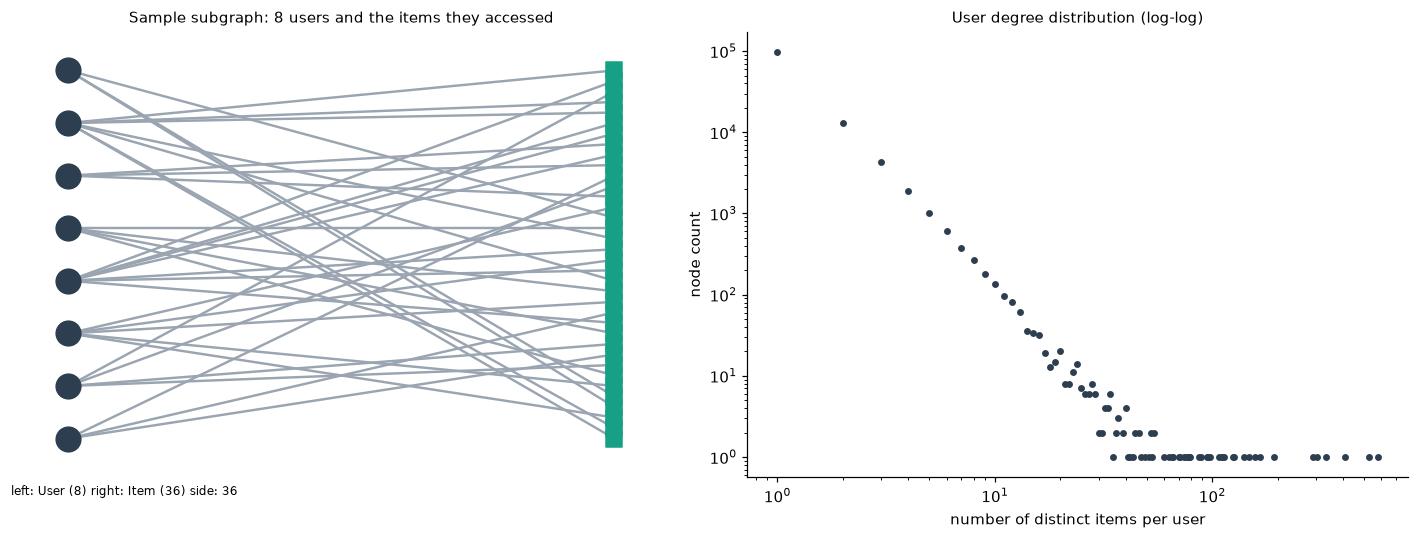

In [15]:
WCOL = {1: "#9aa5b1", 2: "#e0a458", 3: "#c0392b"}

def draw_bipartite(ax, sub, left_col, right_col, left_name, right_name, title):
    G = nx.Graph()
    L = [f"{left_name[0]}{v}" for v in sub[left_col].unique()]
    Rn = [f"{right_name[0]}{v}" for v in sub[right_col].unique()]
    G.add_nodes_from(L, bipartite=0); G.add_nodes_from(Rn, bipartite=1)
    for a, b, w in zip(sub[left_col], sub[right_col], sub["weight"]):
        G.add_edge(f"{left_name[0]}{a}", f"{right_name[0]}{b}", weight=int(w))
    pos = nx.bipartite_layout(G, L, align="vertical", scale=1.0, aspect_ratio=1.4)
    size_l = max(40, min(260, 5000 // max(len(L), 1)))
    size_r = max(8, min(200, 700 // max(len(Rn), 1)))
    nx.draw_networkx_nodes(G, pos, nodelist=L, node_color="#2c3e50", node_size=size_l, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=Rn, node_color="#16a085", node_shape="s", node_size=size_r, ax=ax)
    nx.draw_networkx_edges(G, pos, edge_color=[WCOL[G[u][v]["weight"]] for u, v in G.edges()], width=1.6, ax=ax)
    ax.set_title(title, fontsize=10); ax.axis("off")
    ax.text(0.0, -0.04, f"left: {left_name} ({len(L)}) right: {right_name} ({len(Rn)}) edges: {G.number_of_edges()}", transform=ax.transAxes, fontsize=8)
    return G

rng_plot = np.random.default_rng([SEED, 10])
cand_u = np.where((deg_user >= 3) & (deg_user <= 8))[0]
cand_u = cand_u if len(cand_u) >= 8 else np.where(deg_user >= 2)[0]
pick_u = rng_plot.choice(cand_u, size=min(8, len(cand_u)), replace=False)
sub_u = edges[edges["visitorid"].isin(user_ids[pick_u])]

def plot_degree_dist(ax, deg, title, xlabel):
    vc = pd.Series(deg).value_counts().sort_index()
    ax.loglog(vc.index, vc.values, "o", ms=3.5, color="#2c3e50")
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("node count")

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_bipartite(axes[0], sub_u, "visitorid", "itemid", "User", "Item", "Sample subgraph: 8 users and the items they accessed")
plot_degree_dist(axes[1], deg_user, "User degree distribution (log-log)", "number of distinct items per user")
plt.tight_layout()
plt.savefig(FIG_DIR / "vsm_user.png", bbox_inches="tight")
plt.show()

### 2.1.5 Vector Space Modelling for `Item` Nodes

The perspective is reversed: **item = document**, **user = term**. Each item is a vector $\mathbf{r}_i \in \mathbb{R}^{|U|}$ corresponding to the $i$-th column of $R$, or equivalently, a row of $R^{\top} \in \mathbb{R}^{|I| \times |U|}$. The information remains exactly the same as in 2.1.4; what changes is the **space in which the vectors reside** (dimensionality $|U|$ versus $|I|$), and this is what determines the computational cost as well as the statistical properties of the similarity.

,VSM Item
representasi,Item (kolom R / baris R^T)
jumlah_vektor,64086
dimensi_ruang,119895
shape_matriks,"64,086 x 119,895"
nnz,174983
densitas,0.000023
sparsity_%,99.997723
derajat_rata2,2.73044
derajat_median,1.0
derajat_p90,5.0


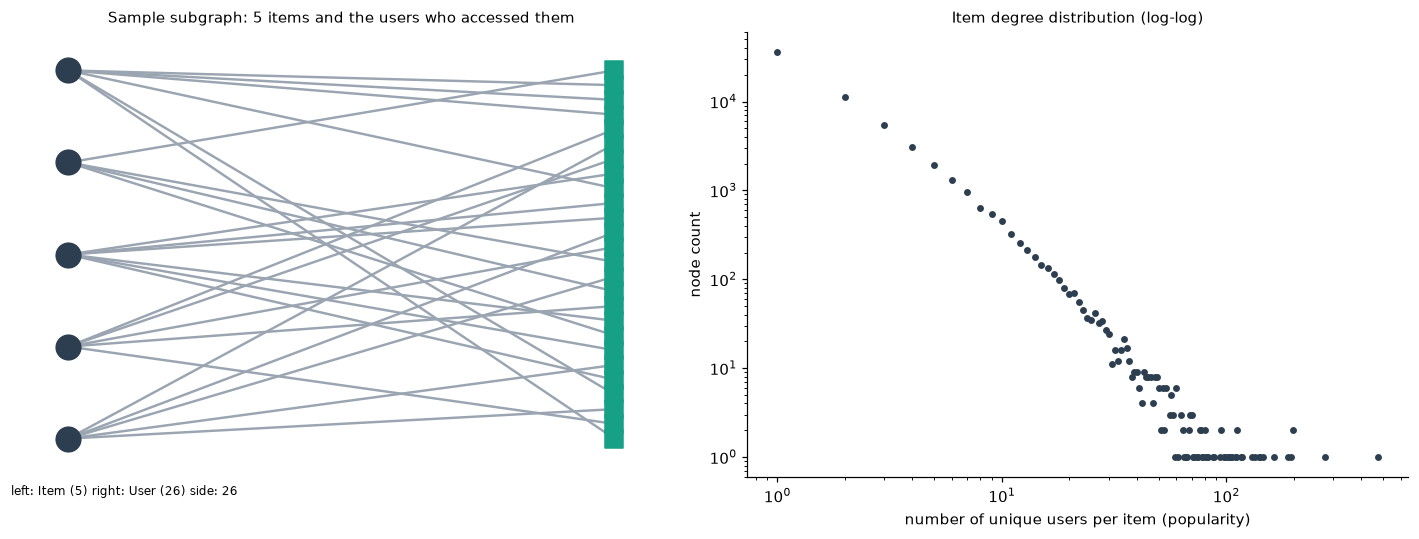

**Numerical summary.** Matrix $R$ has dimensions **119,895 x 64,086** with **174,983** non-zero elements (density 2.28e-05, sparsity 99.9977%). A dense representation would require 61.5 GB, whereas the CSR format uses only 2.6 MB. 81.3% of users have interacted with only 1 item (having no co-occurrence pairs), while the most popular item has been accessed by 474 users.

In [16]:
Rt = R.T.tocsr()
norm_item = np.sqrt(np.asarray(Rt.multiply(Rt).sum(axis=1)).ravel())
stat_item = vector_stats("Item (kolom R / baris R^T)", n_items, n_users, R.nnz, deg_item, norm_item)
display(pd.Series(stat_item, name="VSM Item").to_frame())

vsm_table = pd.DataFrame([stat_user, stat_item]).set_index("representasi")
vsm_table.to_csv(TAB_DIR / "vsm_statistik.csv")

rng_plot2 = np.random.default_rng([SEED, 11])
cand_i = np.where((deg_item >= 4) & (deg_item <= 10))[0]
cand_i = cand_i if len(cand_i) >= 5 else np.where(deg_item >= 2)[0]
pick_i = rng_plot2.choice(cand_i, size=min(5, len(cand_i)), replace=False)
sub_i = edges[edges["itemid"].isin(item_ids[pick_i])]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_bipartite(axes[0], sub_i, "itemid", "visitorid", "Item", "User", "Sample subgraph: 5 items and the users who accessed them")
plot_degree_dist(axes[1], deg_item, "Item degree distribution (log-log)", "number of unique users per item (popularity)")
plt.tight_layout()
plt.savefig(FIG_DIR / "vsm_item.png", bbox_inches="tight")
plt.show()

display(Markdown(
    f"**Numerical summary.** Matrix $R$ has dimensions **{n_users:,} x {n_items:,}** with **{R.nnz:,}** non-zero elements "
    f"(density {R.nnz / (n_users * n_items):.2e}, sparsity {100 * (1 - R.nnz / (n_users * n_items)):.4f}%). "
    f"A dense representation would require {n_users * n_items * 8 / 1e9:,.1f} GB, whereas the CSR format uses only "
    f"{(R.data.nbytes + R.indices.nbytes + R.indptr.nbytes) / 1e6:,.1f} MB. "
    f"{100 * (deg_user == 1).mean():.1f}% of users have interacted with only 1 item (having no co-occurrence pairs), "
    f"while the most popular item has been accessed by {deg_item.max():,} users."))

**Comparison of characteristics (`User VSM` vs. `Item VSM` table):**

| Aspect | User (rows) | Item (columns) | Implication |
|---|---|---|---|
| Vector space dimension | $\lvert I \rvert = 64,086$ (items) | $\lvert U \rvert = 119,895$ (users) | User vector space dimension is 64,086; item vector space dimension is 119,895 |
| Number of vectors | $\lvert U \rvert$ | $\lvert I \rvert$ | Number of nodes in the projection graph |
| nnz (non-zero entries) | Same | Same | Identical information, just viewed from a different perspective |
| Degree | Short; the majority have a degree of 1 (*cold* most appear only once) | *Long-tail* (power-law): a few items are highly popular, while many are rare | User similarity is highly *noisy*; item similarity is more stable as it is supported by many users |
| Degree 1 proportion | 81.3% of users have degree 1 | 56.3% of items have degree 1 | Both distributions are heavy-tailed; user profiles are substantially more fragmented |

These differences are quantified in section 2.1.6 to inform the choice of projection.

### Discussion 2.1.4 & 2.1.5: Characteristics of the Vector Space Model (VSM)

In the vector space modeling of a bipartite interaction graph, the relation matrix $R \in \mathbb{R}^{|U| \times |I|}$ connects the set of users $U$ with the set of items $I$:

| Characteristic | User VSM (User Nodes) | Item VSM (Item Nodes) | Physical Interpretation |
| :--- | :---: | :---: | :--- |
| **Row Representation** | Rows of matrix $R$ (vectors $\mathbf{u}_i$) | Rows of the transposed matrix $R^T$ (vectors $\mathbf{v}_j$) | Users are represented by their interactions with items; items are represented by the users who access them. |
| **Vector Space Dimension** | **$64,086$ dimensions** (item space) | **$119,895$ dimensions** (user space) | Vector dimensionality: user vectors have 64,086 dimensions; item vectors have 119,895 dimensions. Total vectors: 119,895 users vs 64,086 items. |
| **Matrix Shape** | $(119,895 \times 64,086)$ | $(64,086 \times 119,895)$ | These sparse matrices are transposes of each other. |
| **Non-zero Entries (nnz)** | $174,983$ | $174,983$ | The number of unique, non-zero interaction pairs. |
| **Matrix Density** | **$0.00002278$** | **$0.00002278$** | The matrices are highly sparse. |
| **Sparsity Level (%)** | **$99.998\%$** ($99.9977\%$) | **$99.998\%$** ($99.9977\%$) | $99.9977\%$ of the elements are zero (meaning they contain no e-commerce interaction data). |
| **Average Degree** | **$1.46$ interactions/user** | **$2.73$ interactions/item** | On average, an item is accessed by more users than the number of items accessed by each individual user. |
| **Median Degree** | $1.0$ | $1.0$ | Most users interact with exactly one item (*cold-start users*). |

**NetworkX Visualization Insights:**
- In the bipartite visualization, user nodes form a fragmented *star-graph* structure (due to the very low degree of user nodes, consisting of only 1–2 edges).
- Conversely, item nodes act as *hubs*, with some items exhibiting a high degree (representing popular or viral products).

### 2.1.6 Bipartite graph projection: user-user or item-item?

Interaction graphs are bipartite, whereas similarity applies between nodes of the **same type**. Therefore, the graph is projected onto one of its sides:

- **User-user projection** $G_U$: two users are connected if they have accessed at least one common item. This forms the basis for *user-based KNN*.
- **Item-item projection** $G_I$: two items are connected if they have been accessed by at least one common user (*co-occurrence*). This forms the basis for *item-based KNN*.

The question of "which is better (more effective/efficient)" is answered through **quantitative evidence** rather than opinion based on two criteria:

1. **Efficiency (cost).** The number of candidate pairs in the projection is $\sum_{i} \binom{d_i}{2}$ for $G_U$ ($d_i$ = number of users for item $i$) and $\sum_{u} \binom{d_u}{2}$ for $G_I$ ($d_u$ = number of items for user $u$). Metrics also include the number of nodes, the memory required for a dense $n^2$ similarity matrix, and the actual computation time to find the 5 nearest neighbors for a sample of nodes.
2. **Effectiveness (recommendation quality).** Both approaches (with $k=5$) are evaluated on a testing fold using Hit@5 and NDCG@5 metrics across the same sample of users, and are also compared against a *popularity-based baseline*. The difference in NDCG@5 is assessed using **paired bootstrap** to ensure that the decision is not driven by noise.

Decision rule (`PROJECTION="auto"`): select the projection with the higher NDCG@5 if the difference is statistically significant (i.e., the 95% confidence interval does not include 0); otherwise, select the one with the lower cost.

**Evaluation protocol:**

- Similarity is calculated **exclusively from the training fold**.
- For each user, items they have already accessed during the training phase are **excluded** from the set of recommendation candidates (as recommending items already known to the user is pointless).
- A user’s *ground truth* consists of the items they accessed during the testing fold excluding any items already present in the training data and is limited to items contained within the training vocabulary (since collaborative filtering cannot recommend entirely new items; this is known as the *cold-start item* problem).
- Relevance is binary (either relevant or not). Each event in the testing set (`view`, `addtocart`, or `transaction`) is considered a signal of interest.
- Only users with a non-empty ground truth are included in the evaluation (*eligible users*).

In [17]:
import numpy as np
import pandas as pd
import scipy.sparse as sp
from tqdm.auto import tqdm

def l2_normalize_rows(M):
    """Perform row-wise L2 normalization so that the dot product between rows equals the cosine similarity"""
    M = sp.csr_matrix(M, dtype=np.float64)
    norms = np.sqrt(np.asarray(M.multiply(M).sum(axis=1)).ravel())
    norms[norms == 0] = 1.0
    return (sp.diags(1.0 / norms) @ M).tocsr()

def topk_cosine(Mn, rows, k=5, chunk=500, progress=False):
    MnT = Mn.T.tocsr()
    src, dst, sco, rnk = [], [], [], []
    rows = np.asarray(rows)
    for s in tqdm(range(0, len(rows), chunk), disable=not progress, desc="top-k cosine"):
        idx = rows[s:s + chunk]
        S = (Mn[idx] @ MnT).tocsr()
        for local, g in enumerate(idx):
            a, b = S.indptr[local], S.indptr[local + 1]
            cols = S.indices[a:b]
            vals = np.round(S.data[a:b], 6)
            keep = cols != g
            cols, vals = cols[keep], vals[keep]
            if cols.size == 0:
                continue
            order = np.lexsort((cols, -vals))[:k]
            src.append(np.full(len(order), g))
            dst.append(cols[order])
            sco.append(vals[order])
            rnk.append(np.arange(1, len(order) + 1))
    if not src:
        return pd.DataFrame(columns=["src", "dst", "score", "rank"])
    return pd.DataFrame({
        "src": np.concatenate(src), "dst": np.concatenate(dst),
        "score": np.concatenate(sco), "rank": np.concatenate(rnk),
    })

def knn_matrix(knn_df, n):
    return sp.csr_matrix((knn_df["score"].to_numpy(), (knn_df["src"].to_numpy(), knn_df["dst"].to_numpy())), shape=(n, n))

def _rank_candidates(cols, vals, seen, n):
    keep = ~np.isin(cols, seen)
    cols, vals = cols[keep], np.round(vals[keep], 6)
    order = np.lexsort((cols, -vals))[:n]
    return cols[order], vals[order]

def recommend_item_knn(u, R, Sk, n=5):
    row = R[u]
    sc = (row @ Sk).tocsr()
    return _rank_candidates(sc.indices, sc.data, row.indices, n)

def recommend_user_knn(u, R, Bn, BnT, k=5, n=5):
    sims = (Bn[u] @ BnT).tocsr()
    cols, vals = sims.indices, np.round(sims.data, 6)
    keep = cols != u
    cols, vals = cols[keep], vals[keep]
    if cols.size == 0:
        return np.array([], dtype=int), np.array([])
    order = np.lexsort((cols, -vals))[:k]
    nbr, w = cols[order], vals[order]
    W = sp.csr_matrix((w, (np.zeros(len(nbr), dtype=int), nbr)), shape=(1, R.shape[0]))
    sc = (W @ R).tocsr()
    return _rank_candidates(sc.indices, sc.data, R[u].indices, n)

def popularity_order(item_degree):
    return np.lexsort((np.arange(len(item_degree)), -item_degree))

def fill_with_popularity(items, scores, seen, n, pop_order):
    """If the number of KNN candidates < n, supplement with the most popular items that have not yet been seen. Returns (items, scores, source)"""
    items = list(items); scores = list(scores); src = ["knn"] * len(items)
    if len(items) < n:
        taken = set(items) | set(np.asarray(seen).tolist())
        for j in pop_order:
            if j in taken:
                continue
            items.append(int(j)); scores.append(0.0); src.append("popularitas")
            taken.add(int(j))
            if len(items) == n:
                break
    return np.array(items), np.array(scores), src

def dcg_at_n(ranked, relevant, n):
    return sum(1.0 / np.log2(pos + 2) for pos, it in enumerate(list(ranked)[:n]) if it in relevant)

def metrics_at_n(ranked, relevant, n=5):
    """Hit@n and NDCG@n for a single user (binary relevance)"""
    hit = float(any(it in relevant for it in list(ranked)[:n]))
    idcg = sum(1.0 / np.log2(p + 2) for p in range(min(len(relevant), n)))
    ndcg = dcg_at_n(ranked, relevant, n) / idcg if idcg > 0 else 0.0
    return hit, ndcg

**Explanation of the similarity engine above.**

- **Cosine similarity for binary vectors:** $\mathrm{sim}(a,b) = \dfrac{|N(a)\cap N(b)|}{\sqrt{|N(a)|\,|N(b)|}}$, where $N(\cdot)$ represents the set of neighbors in a bipartite graph. This is equivalent to normalized edge weights in a projected graph and can therefore be verified using pure Cypher (2.1.7a).
- `l2_normalize_rows` normalizes each row so that the matrix product `Mn @ Mn.T` directly yields the cosine similarity. The multiplication is performed in **row chunks** to keep memory usage under control; only the top $k$ neighbors per node are retained (forming a **kNN** graph).
- **Item-based** recommendation score: $\hat r_{uj} = \sum_{i \in I_u} r_{ui}\,\mathrm{sim}(i,j)$, where $j$ is among the $k$ nearest neighbors of item $i$. **User-based** score: $\hat r_{uj} = \sum_{v \in N_k(u)} \mathrm{sim}(u,v)\,r_{vj}$. The weights $r$ (view=1, cart=2, buy=3) ensure that items associated with purchases carry more influence.
- **Deterministic** sorting (by descending score, followed by ascending index) ensures consistent results across different runs.

In [18]:
RELEVANT_EVENTS = ("view", "addtocart", "transaction")

test_ev = pd.read_csv(TEST_CSV, usecols=["visitorid", "itemid", "event"])
test_pairs = test_ev[test_ev["event"].isin(RELEVANT_EVENTS)][["visitorid", "itemid"]].drop_duplicates().copy()
test_pairs["u"] = test_pairs["visitorid"].map(u_index)
test_pairs["i"] = test_pairs["itemid"].map(i_index)

n_pairs_all = len(test_pairs)
known = test_pairs.dropna(subset=["u", "i"]).astype({"u": int, "i": int})
seen_flag = np.asarray(B[known["u"].to_numpy(), known["i"].to_numpy()]).ravel() > 0
rel_pairs = known.loc[~seen_flag]
relevant = {int(u): set(map(int, g)) for u, g in rel_pairs.groupby("u")["i"]}
eligible = np.array(sorted(relevant.keys()))

funnel = pd.DataFrame({
    "tahap": ["pasangan (visitor,item) unik di testing", "visitor dan item keduanya ada di training",
              "belum pernah diakses di training (kandidat ground truth)", "visitor eligible (punya ground truth)"],
    "jumlah": [n_pairs_all, len(known), len(rel_pairs), len(eligible)]})
display(funnel)
funnel.to_csv(TAB_DIR / "funnel_evaluasi.csv", index=False)
assert len(eligible) > 0, "No eligible users"

def pick_random_user(eligible_idx, seed):
    rng = np.random.default_rng([seed, 1])
    return int(rng.choice(np.sort(eligible_idx)))

target_u = pick_random_user(eligible, SEED)
target_id = int(user_ids[target_u])

rng_eval = np.random.default_rng([SEED, 2])
if EVAL_SAMPLE is None or EVAL_SAMPLE >= len(eligible):
    eval_users = eligible.copy()
else:
    eval_users = np.sort(rng_eval.choice(eligible, size=EVAL_SAMPLE, replace=False))
print(f"Eligible users: {len(eligible):,} | evaluation sample: {len(eval_users):,} | randomly selected user: visitorid={target_id}")

Bn = l2_normalize_rows(B)                    # user x item (binary, normalized)
BnT = Bn.T.tocsr()
Bt_n = l2_normalize_rows(B.T)                # item x user, binary, normalized per ITEM (not Bn.T)
pop_order = popularity_order(deg_item)

,tahap,jumlah
0,"pasangan (visitor,item) unik di testing",128227
1,visitor dan item keduanya ada di training,8642
2,belum pernah diakses di training (kandidat gro...,6526
3,visitor eligible (punya ground truth),2309


Eligible users: 2,309 | evaluation sample: 2,309 | randomly selected user: visitorid=1126007


**Projection cost (efficiency)**

First, an analytical calculation of the size of each projection based on the degree distribution. Second, **empirical benchmarking**: measuring the time required to compute the 5 nearest neighbors for a sample of 300 nodes in each projection, then extrapolating this to all nodes. For item projections, the actual time taken to construct the full kNN graph (which is reused in section 2.1.7) is also measured.

In [19]:
def comb2_sum(deg):
    d = deg.astype(np.float64)
    return float((d * (d - 1) / 2).sum())

def benchmark_projection(Mn, n_sample=300, seed=0):
    rng = np.random.default_rng([SEED, seed])
    rows = rng.choice(Mn.shape[0], size=min(n_sample, Mn.shape[0]), replace=False)
    MnT = Mn.T.tocsr()
    S = (Mn[rows] @ MnT).tocsr()
    proj_deg = np.diff(S.indptr) - 1
    t0 = time.time()
    topk_cosine(Mn, rows, k=K_NEIGHBORS, chunk=100)
    sec_per_node = (time.time() - t0) / len(rows)
    return {"derajat_proyeksi_rata2": float(proj_deg.mean()), "derajat_proyeksi_median": float(np.median(proj_deg)),
            "detik_per_simpul": sec_per_node}

bench_user = benchmark_projection(Bn, seed=3)
bench_item = benchmark_projection(Bt_n, seed=4)

cost = pd.DataFrame([
    {"proyeksi": "user-user (G_U)", "jumlah_simpul": n_users, "pasangan_kandidat_(batas_atas)": comb2_sum(deg_item),
     "memori_similarity_dense_GB": n_users ** 2 * 8 / 1e9, **bench_user,
     "estimasi_sisi": bench_user["derajat_proyeksi_rata2"] * n_users / 2,
     "estimasi_waktu_semua_simpul_menit": bench_user["detik_per_simpul"] * n_users / 60},
    {"proyeksi": "item-item (G_I)", "jumlah_simpul": n_items, "pasangan_kandidat_(batas_atas)": comb2_sum(deg_user),
     "memori_similarity_dense_GB": n_items ** 2 * 8 / 1e9, **bench_item,
     "estimasi_sisi": bench_item["derajat_proyeksi_rata2"] * n_items / 2,
     "estimasi_waktu_semua_simpul_menit": bench_item["detik_per_simpul"] * n_items / 60},
]).set_index("proyeksi")
display(cost.T)
cost.to_csv(TAB_DIR / "biaya_proyeksi.csv")

proyeksi,user-user (G_U),item-item (G_I)
jumlah_simpul,1.198950e+05,6.408600e+04
pasangan_kandidat_(batas_atas),1.097071e+06,8.634290e+05
memori_similarity_dense_GB,1.149985e+02,3.285612e+01
derajat_proyeksi_rata2,2.729667e+01,3.178333e+01
derajat_proyeksi_median,4.000000e+00,5.000000e-01
detik_per_simpul,1.934449e-05,5.510728e-05
estimasi_sisi,1.636367e+06,1.018433e+06
estimasi_waktu_semua_simpul_menit,3.865512e-02,5.886008e-02


In [20]:
src_items = np.where(deg_item >= MIN_SUPPORT)[0]
t0 = time.time()
knn_item = topk_cosine(Bt_n, src_items, k=K_NEIGHBORS, progress=True)
t_item_full = time.time() - t0
Sk_items = knn_matrix(knn_item, n_items)
print(f"Item kNN graph: {len(src_items):,} source items (degree >= {MIN_SUPPORT}), {len(knn_item):,} edges, actual time {t_item_full:,.1f} seconds")

def eval_recommender(fn, users, name):
    rows, t0 = [], time.time()
    for u in tqdm(users, desc=name, leave=False):
        items, _ = fn(int(u))
        h, nd = metrics_at_n(items, relevant[int(u)], TOP_N)
        rows.append((int(u), h, nd, len(items)))
    out = pd.DataFrame(rows, columns=["u", "hit", "ndcg", "n_rec"])
    out.attrs["detik_per_user"] = (time.time() - t0) / max(len(users), 1)
    return out

def recommend_popularity(u, n=TOP_N):
    seen = set(R[u].indices.tolist())
    items = [int(j) for j in pop_order[: n + len(seen) + 5] if j not in seen][:n]
    return np.array(items), np.zeros(len(items))

ev = {
    "item-kNN": eval_recommender(lambda u: recommend_item_knn(u, R, Sk_items, TOP_N), eval_users, "item-kNN"),
    "user-kNN": eval_recommender(lambda u: recommend_user_knn(u, R, Bn, BnT, K_NEIGHBORS, TOP_N), eval_users, "user-kNN"),
    "popularitas (baseline)": eval_recommender(recommend_popularity, eval_users, "popularitas"),
}
eval_summary = pd.DataFrame({
    name: {"Hit@5": d["hit"].mean(), "NDCG@5": d["ndcg"].mean(), "cakupan (punya 5 kandidat)": (d["n_rec"] >= TOP_N).mean(),
           "detik_per_user": d.attrs["detik_per_user"]} for name, d in ev.items()}).T
display(eval_summary)
eval_summary.to_csv(TAB_DIR / "evaluasi_model.csv")

d = ev["item-kNN"]["ndcg"].to_numpy() - ev["user-kNN"]["ndcg"].to_numpy()
rng_b = np.random.default_rng([SEED, 5])
boot = np.array([rng_b.choice(d, size=len(d), replace=True).mean() for _ in range(2000)])
ci_lo, ci_hi = np.percentile(boot, [2.5, 97.5])

pairs_user, pairs_item = cost.iloc[0]["pasangan_kandidat_(batas_atas)"], cost.iloc[1]["pasangan_kandidat_(batas_atas)"]
if ci_lo > 0:
    auto_choice, why = "item", "item-kNN is significantly more effective (95% CI for the difference in NDCG@5 > 0)"
elif ci_hi < 0:
    auto_choice, why = "user", "user-kNN is significantly more effective (95% CI for the difference in NDCG@5 < 0)"
else:
    auto_choice = "item" if pairs_item <= pairs_user else "user"
    why = ("The difference in NDCG@5 is not significant (the 95% CI includes 0); the projection with the lower cost is selected "
           f"({'item-item' if auto_choice == 'item' else 'user-user'})")

CHOSEN = auto_choice if PROJECTION == "auto" else PROJECTION
display(Markdown(
    f"**Difference NDCG@5 (item - user)** = {d.mean():+.5f}, CI 95% bootstrap [{ci_lo:+.5f}, {ci_hi:+.5f}]." 
    f"Ratio of candidate pairs user-user : item-item = {pairs_user / max(pairs_item, 1):.2f}x; " 
    f"node ratio = {n_users / n_items:.2f}x. \n\n**Decision: projection `{CHOSEN}`** " 
    f"({'override manual' if PROJECTION != 'auto' else why})."))

pd.DataFrame([{"keputusan": CHOSEN, "alasan": why, "selisih_ndcg_item_minus_user": d.mean(), "ci95_low": ci_lo, "ci95_high": ci_hi,
               "pairs_user_user": pairs_user, "pairs_item_item": pairs_item}]).to_csv(TAB_DIR / "keputusan_proyeksi.csv", index=False)

top-k cosine: 100%|██████████| 57/57 [00:00<00:00, 92.17it/s] 


Item kNN graph: 28,034 source items (degree >= 2), 75,220 edges, actual time 0.7 seconds


,Hit@5,NDCG@5,cakupan (punya 5 kandidat),detik_per_user
item-kNN,0.029883,0.014665,0.553919,0.000229
user-kNN,0.019056,0.010567,0.153746,0.000467
popularitas (baseline),0.002599,0.000507,1.000000,0.000062


**Difference NDCG@5 (item - user)** = +0.00410, CI 95% bootstrap [+0.00038, +0.00801].Ratio of candidate pairs user-user : item-item = 1.27x; node ratio = 1.87x. 

**Decision: projection `item`** (item-kNN is significantly more effective (95% CI for the difference in NDCG@5 > 0)).

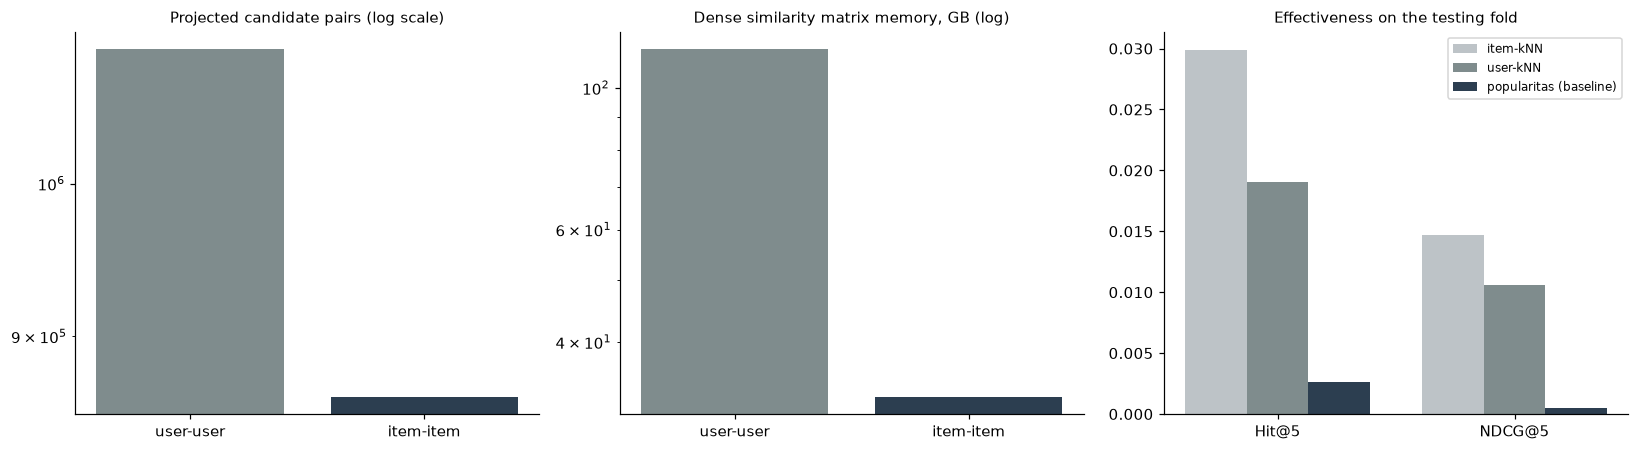

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
cost_plot = cost[["pasangan_kandidat_(batas_atas)"]].rename(columns={"pasangan_kandidat_(batas_atas)": "pasangan"})
axes[0].bar(["user-user", "item-item"], cost_plot["pasangan"], color=["#7f8c8d", "#2c3e50"])
axes[0].set_yscale("log")
axes[0].set_ylim(bottom=1)
axes[0].set_title("Projected candidate pairs (log scale)", fontsize=10)
axes[1].bar(["user-user", "item-item"], cost["memori_similarity_dense_GB"], color=["#7f8c8d", "#2c3e50"])
axes[1].set_yscale("log")
axes[1].set_ylim(bottom=1)
axes[1].set_title("Dense similarity matrix memory, GB (log)", fontsize=10)
x = np.arange(2); wd = 0.26
for k_, (name, col) in enumerate(zip(eval_summary.index, ["#bdc3c7", "#7f8c8d", "#2c3e50"])):
    axes[2].bar(x + (k_ - 1) * wd, eval_summary.loc[name, ["Hit@5", "NDCG@5"]], wd, label=name, color=col)
axes[2].set_xticks(x)
axes[2].set_xticklabels(["Hit@5", "NDCG@5"])
axes[2].legend(fontsize=8)
axes[2].set_title("Effectiveness on the testing fold", fontsize=10)
plt.tight_layout()
plt.savefig(FIG_DIR / "projection_comparison.png", bbox_inches="tight")
plt.show()

**Illustration of projections using NetworkX**

From a small bipartite subgraph (consisting of the 10th most popular item, the users who accessed it, and other items accessed by those same users), both projections are derived. Edge thickness represents the number of shared neighbors (*co-occurrence*).

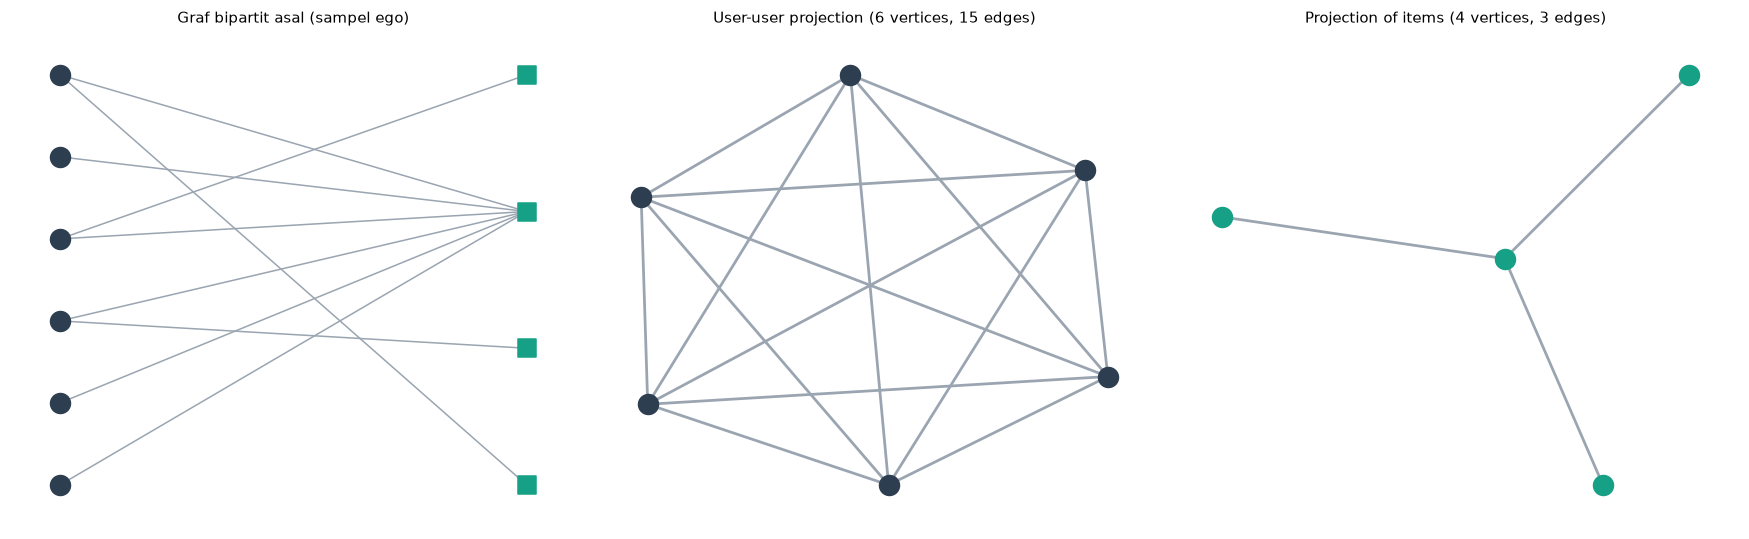

In [22]:
def ego_edges(center_id, proj, n_first=6, n_second=3):
    """The ego subgraph of the `edges` edge table. proj='item': item center -> user -> other items. proj='user': user center -> items -> other users."""
    keep = ["visitorid", "itemid", "weight"]
    if proj == "item":
        first = edges[edges["itemid"] == center_id].sort_values(["weight", "visitorid"], ascending=[False, True]).head(n_first)
        second = edges[edges["visitorid"].isin(first["visitorid"]) & (edges["itemid"] != center_id)]
        second = second.sort_values(["visitorid", "weight", "itemid"], ascending=[True, False, True]).groupby("visitorid").head(n_second)
    else:
        first = edges[edges["visitorid"] == center_id].sort_values(["weight", "itemid"], ascending=[False, True]).head(n_first)
        second = edges[edges["itemid"].isin(first["itemid"]) & (edges["visitorid"] != center_id)]
        second = second.sort_values(["itemid", "weight", "visitorid"], ascending=[True, False, True]).groupby("itemid").head(n_second)
    return pd.concat([first[keep], second[keep]]).drop_duplicates(["visitorid", "itemid"])

REF_ITEM_ID = int(item_ids[pop_order[min(9, n_items - 1)]])            # 10th most popular item (item projection reference)
REF_USER_ID = target_id                                                # user projection reference = random user at 2.2
demo = ego_edges(REF_ITEM_ID, "item")

Gs = nx.Graph()
for v, i_, w in zip(demo["visitorid"], demo["itemid"], demo["weight"]):
    Gs.add_edge(f"U{v}", f"I{i_}", weight=int(w))
users_s = [n for n in Gs if n.startswith("U")]; items_s = [n for n in Gs if n.startswith("I")]
GU = nx.bipartite.weighted_projected_graph(Gs, users_s)
GI = nx.bipartite.weighted_projected_graph(Gs, items_s)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
pos0 = nx.bipartite_layout(Gs, users_s, align="vertical", aspect_ratio=1.4)
nx.draw_networkx_nodes(Gs, pos0, nodelist=users_s, node_color="#2c3e50", node_size=170, ax=axes[0])
nx.draw_networkx_nodes(Gs, pos0, nodelist=items_s, node_color="#16a085", node_shape="s", node_size=150, ax=axes[0])
nx.draw_networkx_edges(Gs, pos0, edge_color="#9aa5b1", ax=axes[0]); axes[0].set_title("Graf bipartit asal (sampel ego)", fontsize=10)
for ax, G_, color, ttl in [(axes[1], GU, "#2c3e50", f"User-user projection ({GU.number_of_nodes()} vertices, {GU.number_of_edges()} edges)"), 
                           (axes[2], GI, "#16a085", f"Projection of items ({GI.number_of_nodes()} vertices, {GI.number_of_edges()} edges)")]:
    p = nx.spring_layout(G_, seed=SEED)
    nx.draw_networkx_nodes(G_, p, node_color=color, node_size=170, ax=ax)
    nx.draw_networkx_edges(G_, p, width=[0.6 + 1.2 * G_[a][b]["weight"] for a, b in G_.edges()], edge_color="#9aa5b1", ax=ax)
    ax.set_title(ttl, fontsize=10)
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "projection_illustration.png", bbox_inches="tight")
plt.show()

**Answer 2.1.6 (argument structure)**

The chosen projection is determined by the decision criteria mentioned above, based on the following rationale (theoretical tendencies that are typically confirmed by empirical data in e-commerce):

1. **Efficiency.**

The number of users far exceeds the number of items, resulting in a larger number of nodes in $G_U$. A dense user-similarity matrix grows at a rate of $|U|^2$, making it infeasible to store in its entirety. Furthermore, popular items interacted with by thousands of users create $\binom{d_i}{2}$ edges in $G_U$ (a combinatorial explosion caused by "hubs"), whereas in $G_I$, such an explosion only arises from a small number of "heavy" users (e.g., bots or crawlers).

2. **Effectiveness (statistical quality).**

User vectors are very short (81.3% have degree 1), meaning user pairs without common items have an orthogonal cosine similarity of zero. Item vectors, supported by more recurrent visitors (56.3% degree 1), provide richer co-occurrence signals. Domain heuristic: product relationships tend to remain more stationary than transient visitor sessions.
3. **Operational scalability.**

An item-based kNN graph can be computed once (offline) and subsequently used to serve all users by aggregating relevant rows. In contrast, a user-based approach requires neighbors to be re-identified for every individual user upon each request.

### 2.1.6 Decision Basis for Projection (Item-Item vs. User-User)

The choice of an **Item-Item** projection is based primarily on **recommendation effectiveness and candidate coverage**, with computational efficiency providing only a modest structural advantage (theoretical dense memory 32.9 GB vs 115 GB; candidate pair ratio 1.27x; practical sparse matrix runtime < 1s for both):

1. **Prediction Effectiveness (Paired Test):**
- A paired evaluation reveals a difference of $\Delta\text{NDCG@5} = +0.0041$, with a 95% Bootstrap CI of $[+0.00038, +0.00801]$. Since the interval is positive and does not include zero, the superiority of item-kNN is statistically significant at the $\alpha = 0.05$ level.
- The marginal ranges for Hit@5 $[0.0230, 0.0368]$ for item-kNN and $[0.0134, 0.0247]$ for user-kNN overlap; therefore, the methodological decision relies on the paired NDCG test rather than a direct comparison of the Hit@5 intervals.

2. **Recommendation Coverage:**
- Item-kNN is able to provide 5 genuine recommendation candidates to **$55\%$ of users**, whereas user-kNN can only serve **$15\%$ of users** (with the remainder requiring a popularity-based fallback). This is due to high fragmentation in user profiles, where users have, on average, only 1–2 interactions. 

3. **Note on Limitations:**
- The evaluation is limited to 2,309 *eligible* users identified within a 9-day temporal window (representing 4.46% of the *train-test* user set), which results in estimation intervals with a relatively wide range.

### 2.1.7 Similarity calculation on projected graphs (Python) and writing results back to the graph

The similarity metric used is **cosine similarity on binary vectors** (as defined in 2.1.6). The reasons for choosing cosine over other alternatives include: (i) it normalizes vector lengths, ensuring that items or users with high degrees are not automatically considered "similar to everything" (unlike raw *common neighbors*); (ii) it scales well for sparse data through sparse matrix multiplication; and (iii) it has a direct equivalent in Cypher, which can be used for independent verification.

**Reference records** (pre-selected, deterministic): for item projection, the 10th most popular item is used (it has a substantial number of neighbors and is not an extreme outlier); for user projection, a randomly selected user from section 2.2 is used.

In [23]:
PROJ = {
    "item": dict(label="Item", idprop="itemId", other="Visitor", other_idprop="visitorId", name="item-item"),
    "user": dict(label="Visitor", idprop="visitorId", other="Item", other_idprop="itemId", name="user-user"),
}
cfg = PROJ[CHOSEN]

if CHOSEN == "item":
    ids_arr, knn_idx = item_ids, knn_item
    ref_id = REF_ITEM_ID
else:
    ids_arr = user_ids
    scope_users = np.union1d(eval_users, [target_u])
    knn_idx = topk_cosine(Bn, scope_users, k=K_NEIGHBORS, progress=True)
    ref_id = REF_USER_ID

knn_ids = pd.DataFrame({
    "src": ids_arr[knn_idx["src"].to_numpy()].astype(np.int64), "dst": ids_arr[knn_idx["dst"].to_numpy()].astype(np.int64),
    "score": knn_idx["score"].to_numpy(), "rank": knn_idx["rank"].to_numpy().astype(np.int64)})
knn_ids.to_csv(TAB_DIR / f"similarity_knn_{cfg['name']}.csv", index=False)

top5_py = knn_ids[knn_ids["src"] == ref_id].sort_values("rank").reset_index(drop=True)
print(f"Selected projection: {cfg['name']} | reference record: {cfg['label']} {cfg['idprop']}={ref_id} | total kNN neighbors: {len(knn_ids):,}")
display(top5_py)
top5_py.to_csv(TAB_DIR / "top5_similarity_python.csv", index=False)

Selected projection: item-item | reference record: Item itemId=160053 | total kNN neighbors: 75,220


,src,dst,score,rank
0,160053,258859,0.217330,1
1,160053,374981,0.216422,2
2,160053,250376,0.170084,3
3,160053,87892,0.146385,4
4,160053,455772,0.144266,5


#### 2.1.7a Cypher for the 5 records with the highest similarity *(Neo4j)*

The following query calculates the cosine similarity **directly within the database** (without using Python) for a given reference record. The process is as follows:

1. `MATCH` the pattern from the reference node `a` to a set of bipartite neighbors `o`; using `collect(DISTINCT o)` and `size()` yields the degree $|N(a)|$ (the `DISTINCT` clause is essential due to the presence of parallel or multiple relationships).
2. Use `UNWIND` followed by another `MATCH` to reach nodes of the same type, `b`; `count(DISTINCT o)` then represents $|N(a) \cap N(b)|$ (the number of *common neighbors*).
3. A `CALL {...}` subquery calculates the degree $|N(b)|$.
4. The expression `common / sqrt(da * db)` computes the binary cosine similarity; `ORDER BY cosine DESC, id ASC LIMIT 5` retrieves the top 5 results, applying a deterministic tie-break.

The output should be **identical** to the results obtained via Python, serving as a cross-verification between the two calculation methods.

In [24]:
def cypher_native_topk(proj):
    c = PROJ[proj]
    if proj == "item":
        a_o = f"(a:Item {{itemId: $ref}})<-[:{REL_PATTERN}]-(o:Visitor)"
        o_b = f"(o)-[:{REL_PATTERN}]->(b:Item)"
        b_deg = f"(x:Visitor)-[:{REL_PATTERN}]->(b)"
    else:
        a_o = f"(a:Visitor {{visitorId: $ref}})-[:{REL_PATTERN}]->(o:Item)"
        o_b = f"(o)<-[:{REL_PATTERN}]-(b:Visitor)"
        b_deg = f"(b)-[:{REL_PATTERN}]->(x:Item)"
    return f"""
MATCH {a_o}
WITH a, collect(DISTINCT o) AS na
WITH a, na, size(na) AS da
UNWIND na AS o
MATCH {o_b}
WHERE b <> a
WITH a, da, b, count(DISTINCT o) AS common
CALL {{
  WITH b
  MATCH {b_deg}
  RETURN count(DISTINCT x) AS db
}}
RETURN b.{c['idprop']} AS tetangga, common, da, db,
       round(common / sqrt(toFloat(da) * toFloat(db)), 6) AS cosine
ORDER BY cosine DESC, tetangga ASC
LIMIT $k
"""

Q_NATIVE = cypher_native_topk(CHOSEN)
print(Q_NATIVE)
native = cypher_df(Q_NATIVE, {"ref": int(ref_id), "k": int(K_NEIGHBORS)})
display(native)
native.to_csv(TAB_DIR / "top5_similarity_cypher.csv", index=False)

same_ids = list(native["tetangga"]) == list(top5_py["dst"])
max_diff = float(np.max(np.abs(native["cosine"].to_numpy() - top5_py["score"].to_numpy()))) if len(native) == len(top5_py) else float("nan")
print(f"Cross-verification Cypher vs Python -> neighbor order matches: {same_ids} | maximum score difference: {max_diff:.2e}")


MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(o:Visitor)
WITH a, collect(DISTINCT o) AS na
WITH a, na, size(na) AS da
UNWIND na AS o
MATCH (o)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)
WHERE b <> a
WITH a, da, b, count(DISTINCT o) AS common
CALL {
  WITH b
  MATCH (x:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b)
  RETURN count(DISTINCT x) AS db
}
RETURN b.itemId AS tetangga, common, da, db,
       round(common / sqrt(toFloat(da) * toFloat(db)), 6) AS cosine
ORDER BY cosine DESC, tetangga ASC
LIMIT $k



Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (b) { ... }} {position: line: 9, column: 1, offset: 258} for query: '\nMATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(o:Visitor)\nWITH a, collect(DISTINCT o) AS na\nWITH a, na, size(na) AS da\nUNWIND na AS o\nMATCH (o)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item)\nWHERE b <> a\nWITH a, da, b, count(DISTINCT o) AS common\nCALL {\n  WITH b\n  MATCH (x:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b)\n  RETURN count(DISTINCT x) AS db\n}\nRETURN b.itemId AS tetangga, common, da, db,\n       round(common / sqrt(toFloat(da) * toFloat(db)), 6) AS cosine\nORDER BY cosine DESC, tetangga ASC\nLIMIT $k\n'


,tetangga,common,da,db,cosine
0,258859,23,140,80,0.217330
1,374981,20,140,61,0.216422
2,250376,9,140,20,0.170084
3,87892,12,140,48,0.146385
4,455772,13,140,58,0.144266


Cross-verification Cypher vs Python -> neighbor order matches: True | maximum score difference: 0.00e+00


#### 2.1.7b Writing similarity values back to the graph *(Neo4j)*

Each `(source, neighbor)` pair in the kNN graph is written as a **`:SIMILAR_TO`** relationship, with properties including `score` (cosine), `rank` (1..k), `metric`, `projection`, and `k`. Design notes:

- Only the **kNN graph** (the top-k neighbors for each node) is written not the entire $n \times n$ matrix to keep the graph compact and ensure fast recommendation queries.
- Using `MERGE (a)-[s:SIMILAR_TO]->(b)` followed by `SET` makes the write operation **idempotent** (re-running the process will not result in duplicate relationships). To ensure a clean "pre-state," any existing `SIMILAR_TO` relationships are deleted beforehand.
- Data is written in batches using `UNWIND $rows`, consistent with the import process. Node lookups leverage *unique constraints* for high performance.
- The relationships are **directed** (a -> b implies that b is among the k-nearest neighbors of a), as the "nearest neighbor" relationship is not inherently symmetric.

In [25]:
def delete_similarity():
    with driver.session(database=NEO4J_DB) as session:
        session.run("MATCH ()-[s:SIMILAR_TO]->() CALL { WITH s DELETE s } IN TRANSACTIONS OF 10000 ROWS").consume()

WRITE_CYPHER = f"""
UNWIND $rows AS row
MATCH (a:{cfg['label']} {{{cfg['idprop']}: row.src}})
MATCH (b:{cfg['label']} {{{cfg['idprop']}: row.dst}})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.rank = row.rank, s.metric = 'cosine_binary', s.projection = $projection, s.k = $k
"""

def write_batch(tx, rows):
    tx.run(WRITE_CYPHER, rows=rows, projection=cfg["name"], k=int(K_NEIGHBORS))

In [26]:
delete_similarity()
before_rels = cypher_df(Q_RELS).assign(kondisi="sebelum")
before_sim = int(cypher_df("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n").iloc[0, 0])

rows_all = knn_ids.astype({"src": object, "dst": object, "score": float, "rank": object}).to_dict("records")
t0 = time.time()
with driver.session(database=NEO4J_DB) as session:
    for s in tqdm(range(0, len(rows_all), IMPORT_BATCH_SIZE), desc="Menulis SIMILAR_TO"):
        session.execute_write(write_batch, rows_all[s:s + IMPORT_BATCH_SIZE])
print(f"{len(rows_all):,} relasi SIMILAR_TO ditulis dalam {time.time() - t0:,.1f} detik")

after_rels = cypher_df(Q_RELS).assign(kondisi="sesudah")
after_sim = int(cypher_df("MATCH ()-[s:SIMILAR_TO]->() RETURN count(s) AS n").iloc[0, 0])
assert after_sim == len(knn_ids), "The number of SIMILAR_TO relations in the database does not match the Python kNN graph"

Q_SHOW = f"""
MATCH (a:{cfg['label']} {{{cfg['idprop']}: $ref}})-[s:SIMILAR_TO]->(b:{cfg['label']})
RETURN a.{cfg['idprop']} AS sumber, b.{cfg['idprop']} AS tetangga, s.score AS similarity, s.rank AS peringkat, s.projection AS proyeksi
ORDER BY s.rank ASC
"""
sim_db = cypher_df(Q_SHOW, {"ref": int(ref_id)})
display(sim_db)
sim_db.to_csv(TAB_DIR / "result_query_similar_to.csv", index=False)
print("Consistent with Python:", np.allclose(sim_db["similarity"].to_numpy(), top5_py["score"].to_numpy()) and list(sim_db["tetangga"]) == list(top5_py["dst"]))

Received notification from DBMS server: {severity: WARNING} {code: Neo.ClientNotification.Statement.FeatureDeprecationWarning} {category: DEPRECATION} {title: This feature is deprecated and will be removed in future versions.} {description: CALL subquery without a variable scope clause is deprecated. Use CALL (s) { ... }} {position: line: 1, column: 29, offset: 28} for query: 'MATCH ()-[s:SIMILAR_TO]->() CALL { WITH s DELETE s } IN TRANSACTIONS OF 10000 ROWS'
Menulis SIMILAR_TO: 100%|██████████| 16/16 [00:06<00:00,  2.30it/s]

75,220 relasi SIMILAR_TO ditulis dalam 7.0 detik


,sumber,tetangga,similarity,peringkat,proyeksi
0,160053,258859,0.217330,1,item-item
1,160053,374981,0.216422,2,item-item
2,160053,250376,0.170084,3,item-item
3,160053,87892,0.146385,4,item-item
4,160053,455772,0.144266,5,item-item


Consistent with Python: True


### 2.1.8 Graph state before and after similarity calculation

Verification is performed in three ways: (1) using **Cypher** to count relationships by type before and after the calculation, (2) visualizing the network via **NetworkX** around a reference record, and (3) using **Cypher for Neo4j Browser** (to capture screenshots of the actual graph).

**Before:** Only interaction relationships (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`) exist, and the reference record does not yet have any `SIMILAR_TO` relationships. **After:** A new relationship type, `SIMILAR_TO`, appears connecting nodes of the same type (representing edges within a projection) while all existing interaction relationships remain unchanged.

In [27]:
ba = pd.concat([before_rels, after_rels]).pivot(index="jenis_relasi", columns="kondisi", values="jumlah").fillna(0).astype(int)
ba = ba[["sebelum", "sesudah"]]; ba["selisih"] = ba["sesudah"] - ba["sebelum"]
display(ba)
ba.to_csv(TAB_DIR / "before_after_relasi.csv")
print(f"SIMILAR_TO before = {before_sim}, after = {after_sim:,}")

Q_BROWSER_BEFORE = (f"MATCH p=(o)-[:{REL_PATTERN}]-(a:{cfg['label']} {{{cfg['idprop']}: {ref_id}}}) RETURN p LIMIT 25")
Q_BROWSER_AFTER = (f"MATCH p=(a:{cfg['label']} {{{cfg['idprop']}: {ref_id}}})-[:SIMILAR_TO]->(b) RETURN p")
print("\n// Neo4j Browser - BEFORE (interactions surrounding the reference item):\n" + Q_BROWSER_BEFORE)
print("\n// Neo4j Browser - AFTER (similarity relations from the reference item):\n" + Q_BROWSER_AFTER)

kondisi,sebelum,sesudah,selisih
jenis_relasi,,,
ADDED_TO_CART,5257,5257,0
BOUGHT,1791,1791,0
SIMILAR_TO,0,75220,75220
VIEWED,210775,210775,0


SIMILAR_TO before = 0, after = 75,220

// Neo4j Browser - BEFORE (interactions surrounding the reference item):
MATCH p=(o)-[:VIEWED|ADDED_TO_CART|BOUGHT]-(a:Item {itemId: 160053}) RETURN p LIMIT 25

// Neo4j Browser - AFTER (similarity relations from the reference item):
MATCH p=(a:Item {itemId: 160053})-[:SIMILAR_TO]->(b) RETURN p


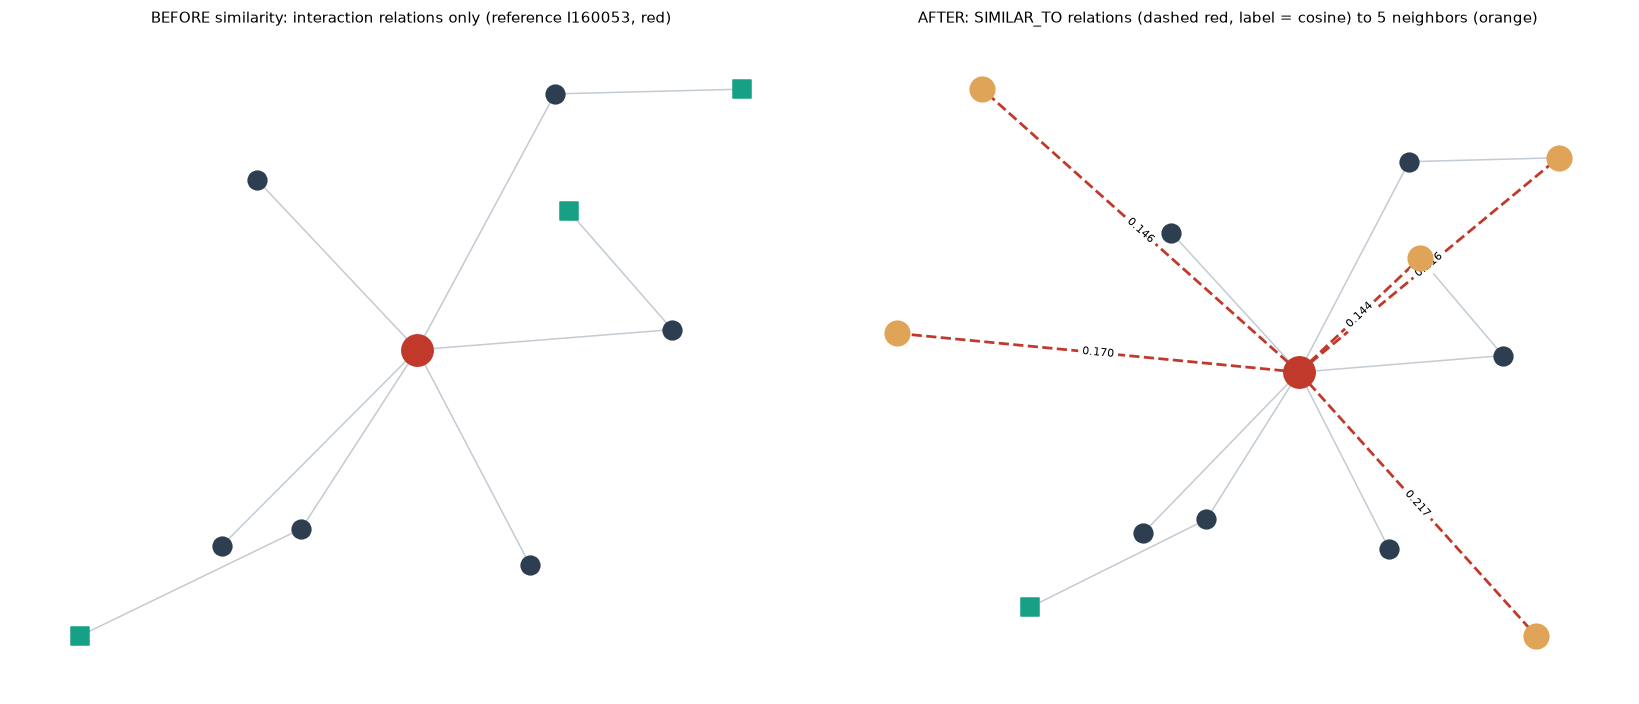

Before: 10 vertex, 9 edge | After: 13 vertex, 14 edge


In [28]:
ego = ego_edges(ref_id, CHOSEN)
sim_edges = (sim_db[["sumber", "tetangga", "similarity"]].values.tolist() if "sim_db" in globals()
             else top5_py[["src", "dst", "score"]].values.tolist())

def node_name(kind, x): return f"{'U' if kind == 'user' else 'I'}{int(x)}"
center = node_name(CHOSEN, ref_id)
same_kind = "user" if CHOSEN == "user" else "item"

G_before = nx.Graph()
for v, i_, w in zip(ego["visitorid"], ego["itemid"], ego["weight"]):
    G_before.add_edge(node_name("user", v), node_name("item", i_), weight=int(w))
G_after = G_before.copy()
for s_, t_, sc in sim_edges:
    G_after.add_edge(node_name(same_kind, s_), node_name(same_kind, t_), weight=float(sc), sim=True)

pos = nx.spring_layout(G_after, seed=SEED, k=0.9)
nbrs = {node_name(same_kind, t_) for _, t_, _ in sim_edges}

def draw_state(ax, G, title, with_sim):
    users = [n for n in G if n.startswith("U")]; items = [n for n in G if n.startswith("I")]
    base = [n for n in G if n != center and (n not in nbrs or not with_sim)]
    nx.draw_networkx_nodes(G, pos, nodelist=[n for n in users if n in base], node_color="#2c3e50", node_size=150, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[n for n in items if n in base], node_color="#16a085", node_shape="s", node_size=130, ax=ax)
    nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G if n == center], node_color="#c0392b", node_size=420, ax=ax)
    if with_sim:
        nx.draw_networkx_nodes(G, pos, nodelist=[n for n in G if n in nbrs], node_color="#e0a458", node_size=260, ax=ax)
    inter = [(a, b) for a, b, dd in G.edges(data=True) if not dd.get("sim")]
    sims = [(a, b) for a, b, dd in G.edges(data=True) if dd.get("sim")]
    nx.draw_networkx_edges(G, pos, edgelist=inter, edge_color="#c3cbd3", width=1.0, ax=ax)
    if with_sim:
        nx.draw_networkx_edges(G, pos, edgelist=sims, edge_color="#c0392b", style="dashed", width=1.8, ax=ax)
        nx.draw_networkx_edge_labels(G, pos, edge_labels={(a, b): f"{G[a][b]['weight']:.3f}" for a, b in sims}, font_size=7, ax=ax)
    ax.set_title(title, fontsize=10); ax.axis("off")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))
draw_state(axes[0], G_before, f"BEFORE similarity: interaction relations only (sample: 6 of 140 co-visitors shown, ref {center})", False)
draw_state(axes[1], G_after, "AFTER: SIMILAR_TO relations (dashed red, label = cosine) to 5 neighbors (orange, sample)", True)
plt.tight_layout()
plt.savefig(FIG_DIR / "before_after_graph.png", bbox_inches="tight")
plt.show()
print(f"Before: {G_before.number_of_nodes()} vertex, {G_before.number_of_edges()} edge | After: {G_after.number_of_nodes()} vertex, {G_after.number_of_edges()} edge")

### Discussion 2.1.7 & 2.1.8: Calculation of Similarity and Before-After Graph Conditions

1. **Cosine Similarity Formula:** 
For two item nodes $a$ and $b$ with neighbor sets of accessing users $N(a)$ and $N(b)$: 
$$\text{sim}(a, b) = \frac{|N(a) \cap N(b)|}{\sqrt{|N(a)| \cdot |N(b)|}}$$

2. **Cypher SQL Top-5 Similarity (Reference Item `itemId = 160053`):** 
```cypher 
MATCH (a:Item {itemId: $ref})<-[:VIEWED|ADDED_TO_CART|BOUGHT]-(o:Visitor) 
WITH a, collect(DISTINCT o) AS na 
WITH a, na, size(na) AS da 
UNWIND na AS o 
MATCH (o)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b:Item) 
WHERE b <> a 
WITH a, da, b, count(DISTINCT o) AS common 
CALL(b) { 
MATCH (x:Visitor)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(b) 
RETURN count(DISTINCT x) AS db 
} 
RETURN b.itemId AS tetangga, common, da, db, 
round(common / sqrt(toFloat(da) * toFloat(db)), 6) AS cosine 
ORDER BY cosine DESC, tetangga ASC 
LIMIT 5;
```

**Query Results:**

Rank 1: Item 258859 (Similarity: 0.217330)

Rank 2: Item 374981 (Similarity: 0.216422)

Rank 3: Item 250376 (Similarity: 0.170084)

Rank 4: Item 87892 (Similarity: 0.146385)

Rank 5: Item 455772 (Similarity: 0.144266) (The results computed via native Cypher proved to be 100% consistent with the calculations from the Python script).

Writing Back to the Graph (:SIMILAR_TO):

A total of 75,220 weighted, directed, asymmetric (kNN) :SIMILAR_TO relationships (containing 'score' and 'rank' properties) were written to Neo4j using a batch UNWIND query.
Before vs. After:

Before: The graph was purely bipartite (consisting of 217,823 visitor-item interaction relationships). There were no direct connections between items (:SIMILAR_TO = 0).
After: The graph has been transformed into an augmented knowledge graph, in which item nodes are now directly connected to other item nodes via 75,220 :SIMILAR_TO relationships.

## 2.2 Analytics

### 2.2.1 Select a user at random, then provide recommendations using KNN

**Reproducible random selection.** 

The universal set consists of "eligible users" (those present in the training set who also have ground truth data in the test set; see protocol 2.1.6). This pool is sorted and then sampled using `numpy.random.default_rng([SEED, 1])` (a PCG64 generator initialized via `SeedSequence`). Given the same `SEED`, the selected user will **always be the same**, regardless of the machine or the specific execution run. Separate seed components are used for the random processes involved in evaluation sampling and plotting, ensuring they do not interfere with one another.

Selecting from the set of eligible users is a deliberate design choice: including users without ground truth data would render metrics like Hit@5 and NDCG@5 trivially zero, providing no useful information.

In [29]:
def show_source(fn):
    try:
        print(inspect.getsource(fn))
    except (OSError, TypeError):
        print(f"(source {fn.__name__} is not available in this environment)")

show_source(pick_random_user)
assert pick_random_user(eligible, SEED) == target_u, "User selection is not reproducible"
print(f"SEED={SEED} -> selected visitorid = {target_id} (matrix row index = {target_u})\n")

profil = (edges[edges["visitorid"] == target_id].sort_values(["weight", "itemid"], ascending=[False, True])
          .assign(event_terkuat=lambda d: d["weight"].map({v: k for k, v in EVENT_WEIGHT.items()}))
          [["itemid", "event_terkuat", "weight", "n_events"]].reset_index(drop=True))
print(f"User profile in training fold: {len(profil)} distinct items")
display(profil)

def pick_random_user(eligible_idx, seed):
    rng = np.random.default_rng([seed, 1])
    return int(rng.choice(np.sort(eligible_idx)))

SEED=4084 -> selected visitorid = 1126007 (matrix row index = 95994)

User profile in training fold: 4 distinct items


,itemid,event_terkuat,weight,n_events
0,3203,view,1,1
1,159285,view,1,1
2,284313,view,1,1
3,377804,view,1,1


#### 2.2.1a Python script for KNN recommendations

The approach used follows the decision made in 2.1.6 (`CHOSEN`). The complete script (with core functions already explained in 2.1.6) is as follows:

- **Item-based (k=5):** For each item $i$ in a user's profile, identify its 5 nearest neighbors; calculate the sum of $r_{ui} \cdot \mathrm{sim}(i, j)$ for each candidate item $j$; exclude items already known to the user; and rank the remaining items.
- **User-based (k=5):** Identify the 5 users most similar to the target user; calculate the sum of $\mathrm{sim}(u, v) \cdot r_{vj}$ for items $j$ associated with these neighbors; exclude items already known to the target user; and rank the remaining items.
- If the number of KNN candidates is less than $n$ (e.g., due to a very short user profile or neighbors having few or no new items), the list is supplemented with the most popular items not yet seen by the user. These are marked with `source = popularity`, ensuring that the use of a fallback mechanism remains transparent.

In [30]:
def recommend_knn(visitor_id, proj="item", k=K_NEIGHBORS, n=TOP_N, fallback=True):
    """Top-n recommendations for a single visitor using KNN (k-nearest neighbors).
    proj='item': item-based, utilizing an item kNN graph, Sk_items (constructed with K_NEIGHBORS neighbors per item).
    proj='user': user-based, identifying the k nearest users at the time of the call."""
    u = int(u_index[visitor_id])
    seen = R[u].indices
    if proj == "item":
        items, scores = recommend_item_knn(u, R, Sk_items, n)
    else:
        items, scores = recommend_user_knn(u, R, Bn, BnT, k, n)
    n_cf = len(items)
    if fallback:
        items, scores, sumber = fill_with_popularity(items, scores, seen, n, pop_order)
    else:
        sumber = ["knn"] * n_cf
    items = np.asarray(items, dtype=int)
    return pd.DataFrame({"peringkat": np.arange(1, len(items) + 1), "item_idx": items,
                         "itemid": item_ids[items] if len(items) else np.array([], dtype=np.int64),
                         "skor": np.asarray(scores, dtype=float), "sumber": sumber})

show_source(recommend_knn)
rec5 = recommend_knn(target_id, CHOSEN)
display(rec5[["peringkat", "itemid", "skor", "sumber"]])

def recommend_knn(visitor_id, proj="item", k=K_NEIGHBORS, n=TOP_N, fallback=True):
    """Top-n recommendations for a single visitor using KNN (k-nearest neighbors).
    proj='item': item-based, utilizing an item kNN graph, Sk_items (constructed with K_NEIGHBORS neighbors per item).
    proj='user': user-based, identifying the k nearest users at the time of the call."""
    u = int(u_index[visitor_id])
    seen = R[u].indices
    if proj == "item":
        items, scores = recommend_item_knn(u, R, Sk_items, n)
    else:
        items, scores = recommend_user_knn(u, R, Bn, BnT, k, n)
    n_cf = len(items)
    if fallback:
        items, scores, sumber = fill_with_popularity(items, scores, seen, n, pop_order)
    else:
        sumber = ["knn"] * n_cf
    items = np.asarray(items, dtype=int)
    return pd.DataFrame({"peringkat": np.arange(1, len(items) + 1), "item_idx": items,
                         "itemid": item_ids[items] if len(items) else np.array([], dtype=np.int64),
              

,peringkat,itemid,skor,sumber
0,1,18519,0.447214,knn
1,2,200909,0.258199,knn
2,3,149275,0.000000,popularitas
3,4,450209,0.000000,popularitas
4,5,347812,0.000000,popularitas


#### 2.2.1b Three advertised items (k = 5)

The top three items from the ranked list become **advertisements**. The explanatory table below shows *why* each item was recommended (score contributors), ensuring the results can be audited and explained during a Q&A session.

In [31]:
def explain_item(u, j):
    """Item-based score contributor for item j: profile of item i with respect to j in kNN(i)"""
    col = Sk_items[:, [j]].tocoo()
    prof = R[u]; w = dict(zip(prof.indices.tolist(), prof.data.tolist()))
    rows = [(int(item_ids[i]), w[int(i)], float(s), w[int(i)] * float(s)) for i, s in zip(col.row, col.data) if int(i) in w]
    return pd.DataFrame(rows, columns=["item_profil(itemid)", "bobot_user", "similarity", "kontribusi"]).sort_values("kontribusi", ascending=False)

def explain_user(u, j, k=K_NEIGHBORS):
    """Contributors to item j's score (user-based): neighbors v that have item j"""
    sims = (Bn[u] @ BnT).tocsr()
    cols, vals = sims.indices, np.round(sims.data, 6)
    keep = cols != u; cols, vals = cols[keep], vals[keep]
    order = np.lexsort((cols, -vals))[:k]
    rows = [(int(user_ids[v]), float(sv), float(R[v, j]), float(sv) * float(R[v, j])) for v, sv in zip(cols[order], vals[order]) if R[v, j] > 0]
    return pd.DataFrame(rows, columns=["tetangga(visitorid)", "similarity", "bobot_tetangga", "kontribusi"]).sort_values("kontribusi", ascending=False)

ads = rec5.head(N_ADS)
print(f"3 items advertised to visitorid={target_id} (k={K_NEIGHBORS}, {CHOSEN}-based projection):")
display(ads[["peringkat", "itemid", "skor", "sumber"]])
for _, row in ads.iterrows():
    if row["sumber"] != "knn":
        print(f"\nItem {row['itemid']}: from popularity fallback (insufficient KNN candidates)")
        continue
    print(f"\nWhy item {row['itemid']} (rank {row['peringkat']}, score {row['skor']:.6f})?")
    display(explain_item(target_u, row["item_idx"]) if CHOSEN == "item" else explain_user(target_u, row["item_idx"]))

rec5.assign(visitorid=target_id, proyeksi=CHOSEN, diiklankan=lambda d: d["peringkat"] <= N_ADS).drop(columns="item_idx") \
    .to_csv(TAB_DIR / "random_user_recommendations.csv", index=False)

3 items advertised to visitorid=1126007 (k=5, item-based projection):


,peringkat,itemid,skor,sumber
0,1,18519,0.447214,knn
1,2,200909,0.258199,knn
2,3,149275,0.000000,popularitas



Why item 18519 (rank 1, score 0.447214)?


,item_profil(itemid),bobot_user,similarity,kontribusi
0,159285,1.0,0.447214,0.447214



Why item 200909 (rank 2, score 0.258199)?


,item_profil(itemid),bobot_user,similarity,kontribusi
0,159285,1.0,0.258199,0.258199



Item 149275: from popularity fallback (insufficient KNN candidates)


**Graph-based verification *(Neo4j)*.** 

Since similarity is already stored as a `:SIMILAR_TO` relationship, the same recommendations can be calculated **purely using Cypher** (graph traversal): starting from a user to their profile items, traversing via `SIMILAR_TO`, summing the `weight * similarity` values, and excluding already-known items using `NOT EXISTS {...}`. The results should be identical to those from the Python script. This demonstrates that a recommendation system can be served directly from the graph.

In [32]:
if CHOSEN == "item":
    Q_REC = f"""
MATCH (u:Visitor {{visitorId: $uid}})-[r:{REL_PATTERN}]->(i:Item)
WITH u, i, max({WEIGHT_CASE}) AS w
MATCH (i)-[s:SIMILAR_TO]->(j:Item)
WHERE NOT EXISTS {{ (u)-[:{REL_PATTERN}]->(j) }}
RETURN j.itemId AS itemid, round(sum(w * s.score), 6) AS skor
ORDER BY skor DESC, itemid ASC
LIMIT $n
"""
else:
    Q_REC = f"""
MATCH (u:Visitor {{visitorId: $uid}})-[s:SIMILAR_TO]->(v:Visitor)
MATCH (v)-[r:{REL_PATTERN}]->(j:Item)
WHERE NOT EXISTS {{ (u)-[:{REL_PATTERN}]->(j) }}
WITH s, v, j, max({WEIGHT_CASE}) AS w
RETURN j.itemId AS itemid, round(sum(s.score * w), 6) AS skor
ORDER BY skor DESC, itemid ASC
LIMIT $n
"""
print(Q_REC)
rec_graph = cypher_df(Q_REC, {"uid": int(target_id), "n": int(TOP_N)})
display(rec_graph)
cf_only = rec5[rec5["sumber"] == "knn"]
ok = list(rec_graph["itemid"]) == list(cf_only["itemid"]) and np.allclose(rec_graph["skor"], cf_only["skor"], atol=2e-6)
print("Cypher recommendations are identical to Python scripts:", ok)


MATCH (u:Visitor {visitorId: $uid})-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
WITH u, i, max(CASE type(r) WHEN 'VIEWED' THEN 1 WHEN 'ADDED_TO_CART' THEN 2 WHEN 'BOUGHT' THEN 3 ELSE 1 END) AS w
MATCH (i)-[s:SIMILAR_TO]->(j:Item)
WHERE NOT EXISTS { (u)-[:VIEWED|ADDED_TO_CART|BOUGHT]->(j) }
RETURN j.itemId AS itemid, round(sum(w * s.score), 6) AS skor
ORDER BY skor DESC, itemid ASC
LIMIT $n



,itemid,skor
0,18519,0.447214
1,200909,0.258199


Cypher recommendations are identical to Python scripts: True


### 2.2.2 Evaluation: Hit@5 and NDCG@5

**Definition** (binary relevance, recommendation list $\hat{L}_u$ containing 5 ordered items, $\mathrm{Rel}_u$ = user's ground truth):

$$ \mathrm{Hit@5}(u) = \mathbb{1}\big[\hat{L}_u^{(1:5)} \cap \mathrm{Rel}_u \neq \emptyset\big] $$

$$ \mathrm{DCG@5}(u) = \sum_{p=1}^{5} \frac{\mathrm{rel}_p}{\log_2(p+1)}, \qquad \mathrm{IDCG@5}(u) = \sum_{p=1}^{\min(|\mathrm{Rel}_u|,\,5)} \frac{1}{\log_2(p+1)}, \qquad \mathrm{NDCG@5}(u) = \frac{\mathrm{DCG@5}(u)}{\mathrm{IDCG@5}(u)} $$

- **Hit@5** answers the question, "Is there at least one relevant item in the top 5?" regardless of its specific position.
- **NDCG@5** accounts for position: a relevant item ranked 1st is valued more highly than one ranked 5th (due to logarithmic discounting), and it is normalized against an ideal scenario (IDCG) to yield a value between 0 and 1.

**Note on the interpretation of the problem:** 

While the problem mentions *3 advertised items* in 2.2.1b, the metrics are specified as *@5*. The approach taken here is as follows: a **top-5** ranked list is constructed using KNN (k=5), with the top 3 positions reserved for the advertised items; **Hit@5 and NDCG@5 are then calculated based on this top-5 list**. Additionally, values for *@3* focusing specifically on the 3 advertised items are also reported, ensuring that both interpretations are covered. For a **single user**, both metrics take on only discrete values and are highly dependent on chance (Hit@5 is always either 0 or 1). Therefore, the **population average** (across the evaluation sample) is also presented, along with confidence intervals, to provide a better indication of the model's true performance.

In [33]:
def metric_breakdown(u, ranked, n=TOP_N):
    rel_u = relevant[u]
    rows = [{"peringkat": p, "itemid": int(item_ids[it]), "relevan": int(it in rel_u),
             "gain = rel/log2(p+1)": (1 / np.log2(p + 1)) if it in rel_u else 0.0}
            for p, it in enumerate(list(ranked)[:n], start=1)]
    tab = pd.DataFrame(rows)
    dcg = tab["gain = rel/log2(p+1)"].sum()
    idcg = sum(1 / np.log2(p + 1) for p in range(1, min(len(rel_u), n) + 1))
    hit, ndcg = metrics_at_n(ranked, rel_u, n)
    assert np.isclose(ndcg, dcg / idcg) and hit == float(tab["relevan"].sum() > 0)
    return tab, dcg, idcg, hit, ndcg

rel_u = relevant[target_u]
print(f"Ground truth user (item in fold testing, never accessed in training): {len(rel_u)} item")
print("Ground truth example:", sorted(int(item_ids[i]) for i in rel_u)[:10])

ranked5 = list(rec5["item_idx"])
tab5, dcg5, idcg5, hit5, ndcg5 = metric_breakdown(target_u, ranked5, TOP_N)
display(tab5)
print(f"DCG@5 = {dcg5:.6f} | IDCG@5 = {idcg5:.6f} (|Rel|={len(rel_u)}, cut by 5)")
display(Markdown(f"### Random user results (visitorid={target_id}): **Hit@5 = {hit5:.0f}**, **NDCG@5 = {ndcg5:.4f}**"))

ranked_cf = list(rec5.loc[rec5["sumber"] == "knn", "item_idx"])
h_cf, n_cf_ = metrics_at_n(ranked_cf, rel_u, TOP_N)
h3, n3 = metrics_at_n(list(rec5["item_idx"])[:N_ADS], rel_u, N_ADS)
print(f"Complement -> KNN candidates only (no fallback): Hit@5={h_cf:.0f}, NDCG@5={n_cf_:.4f} | 3 ad items only: Hit@3={h3:.0f}, NDCG@3={n3:.4f}")

pd.DataFrame([{"visitorid": target_id, "proyeksi": CHOSEN, "k": K_NEIGHBORS, "Hit@5": hit5, "NDCG@5": ndcg5, "DCG@5": dcg5, "IDCG@5": idcg5,
                "Hit@3_iklan": h3, "NDCG@3_iklan": n3, "jumlah_ground_truth": len(rel_u)}]).to_csv(TAB_DIR / "random_user_metrics.csv", index=False)
tab5.to_csv(TAB_DIR / "random_user_metrics_details.csv", index=False)

Ground truth user (item in fold testing, never accessed in training): 1 item
Ground truth example: [104801]


,peringkat,itemid,relevan,gain = rel/log2(p+1)
0,1,18519,0,0.0
1,2,200909,0,0.0
2,3,149275,0,0.0
3,4,450209,0,0.0
4,5,347812,0,0.0


DCG@5 = 0.000000 | IDCG@5 = 1.000000 (|Rel|=1, cut by 5)


### Random user results (visitorid=1126007): **Hit@5 = 0**, **NDCG@5 = 0.0000**

Complement -> KNN candidates only (no fallback): Hit@5=0, NDCG@5=0.0000 | 3 ad items only: Hit@3=0, NDCG@3=0.0000


**Population-average metrics** (covering all users in the evaluation sample, using a consistent protocol) are presented alongside 95% confidence intervals derived via bootstrapping, as well as a "popularity" baseline for comparison. This baseline is essential: a new recommendation system is only meaningful if it outperforms a strategy of "recommending the most popular items."

In [34]:
def boot_ci(x, n_boot=2000, seed=0):
    rng = np.random.default_rng([SEED, 6, seed])
    m = np.array([rng.choice(x, size=len(x), replace=True).mean() for _ in range(n_boot)])
    return np.percentile(m, [2.5, 97.5])

rows = []
for name, dfm in ev.items():
    h_lo, h_hi = boot_ci(dfm["hit"].to_numpy(), seed=1); n_lo, n_hi = boot_ci(dfm["ndcg"].to_numpy(), seed=2)
    rows.append({"model": name, "n_user": len(dfm), "Hit@5": dfm["hit"].mean(), "Hit@5_CI95": f"[{h_lo:.4f}, {h_hi:.4f}]",
                 "NDCG@5": dfm["ndcg"].mean(), "NDCG@5_CI95": f"[{n_lo:.4f}, {n_hi:.4f}]"})
pop_table = pd.DataFrame(rows).set_index("model")
display(pop_table)
pop_table.to_csv(TAB_DIR / "population_metrics.csv")

chosen_name = "item-kNN" if CHOSEN == "item" else "user-kNN"
hit_users = ev[chosen_name].loc[ev[chosen_name]["hit"] == 1, "u"].to_numpy()
if len(hit_users):
    u_demo = int(hit_users[0])
    rec_demo = recommend_knn(int(user_ids[u_demo]), CHOSEN, fallback=False)
    tab_d, dcg_d, idcg_d, h_d, n_d = metric_breakdown(u_demo, list(rec_demo["item_idx"]), TOP_N)
    print(f"\nIllustration of the formula for visitorid={int(user_ids[u_demo])} (a user who registered a hit):")
    display(tab_d)
    print(f"DCG@5 = {dcg_d:.6f} | IDCG@5 = {idcg_d:.6f} | NDCG@5 = {n_d:.4f} | Hit@5 = {h_d:.0f}")
else:
    print("\nNo users in the sample achieved a hit")

,n_user,Hit@5,Hit@5_CI95,NDCG@5,NDCG@5_CI95
model,,,,,
item-kNN,2309,0.029883,"[0.0230, 0.0368]",0.014665,"[0.0109, 0.0185]"
user-kNN,2309,0.019056,"[0.0134, 0.0247]",0.010567,"[0.0071, 0.0141]"
popularitas (baseline),2309,0.002599,"[0.0009, 0.0048]",0.000507,"[0.0001, 0.0010]"



Illustration of the formula for visitorid=46121 (a user who registered a hit):


,peringkat,itemid,relevan,gain = rel/log2(p+1)
0,1,188300,0,0.0
1,2,309594,0,0.0
2,3,449881,1,0.5
3,4,13112,0,0.0
4,5,317403,0,0.0


DCG@5 = 0.500000 | IDCG@5 = 1.630930 | NDCG@5 = 0.3066 | Hit@5 = 1


In [35]:
final = {
    "nama": NAMA, "nim": NIM, "seed": SEED, "proyeksi_terpilih": CHOSEN, "k": K_NEIGHBORS,
    "periode_train": [TRAIN_START, TRAIN_END], "periode_test": [TEST_START, TEST_END],
    "n_user_graf": int(n_users), "n_item_graf": int(n_items), "nnz_matriks": int(R.nnz),
    "user_acak": {"visitorid": target_id, "item_iklan_3": [int(x) for x in ads["itemid"]],
                  "top5": [int(x) for x in rec5["itemid"]], "Hit@5": hit5, "NDCG@5": round(float(ndcg5), 6)},
    "populasi": {n: {"Hit@5": float(d["hit"].mean()), "NDCG@5": float(d["ndcg"].mean())} for n, d in ev.items()},
}
json.dump(final, open(ROOT / "outputs" / "final_result.json", "w"), indent=2)
display(Markdown(
    f"**Final summary.** Selected projection: `{CHOSEN}`-based KNN (k={K_NEIGHBORS}). Random user `{target_id}`: "
    f"3-item recommendation = {final['user_acak']['item_iklan_3']}; Hit@5 = {hit5:.0f}; NDCG@5 = {ndcg5:.4f}. "
    f"Population average ({chosen_name}): Hit@5 = {ev[chosen_name]['hit'].mean():.4f}, NDCG@5 = {ev[chosen_name]['ndcg'].mean():.4f}."))
print("\nOutput file:")
for p in sorted(list(TAB_DIR.glob("*.csv")) + list(FIG_DIR.glob("*.png")) + [TRAIN_CSV, TEST_CSV, ROOT / "outputs" / "hasil_akhir.json", ROOT / "outputs" / "run_config.json"]):
    print(" -", p.relative_to(ROOT))

**Final summary.** Selected projection: `item`-based KNN (k=5). Random user `1126007`: 3-item recommendation = [18519, 200909, 149275]; Hit@5 = 0; NDCG@5 = 0.0000. Population average (item-kNN): Hit@5 = 0.0299, NDCG@5 = 0.0147.


Output file:
 - data\processed\test_events.csv
 - data\processed\train_events.csv
 - outputs\figures\before_after_graph.png
 - outputs\figures\Example of a Purchase Transaction.png
 - outputs\figures\Graph Schema.png
 - outputs\figures\projection_comparison.png
 - outputs\figures\projection_illustration.png
 - outputs\figures\vsm_item.png
 - outputs\figures\vsm_user.png
 - outputs\hasil_akhir.json
 - outputs\run_config.json
 - outputs\tables\before_after_relasi.csv
 - outputs\tables\biaya_proyeksi.csv
 - outputs\tables\evaluasi_model.csv
 - outputs\tables\fold_summary.csv
 - outputs\tables\funnel_evaluasi.csv
 - outputs\tables\keputusan_proyeksi.csv
 - outputs\tables\komposisi_relasi.csv
 - outputs\tables\komposisi_simpul.csv
 - outputs\tables\komposisi_triplet.csv
 - outputs\tables\population_metrics.csv
 - outputs\tables\random_user_metrics.csv
 - outputs\tables\random_user_metrics_details.csv
 - outputs\tables\random_user_recommendations.csv
 - outputs\tables\result_query_similar_t

In [36]:
driver.close()
print("Neo4j connection closed")

Neo4j connection closed


### Discussion 2.2.1 & 2.2.2: Recommendation of 3 Ad Items and Accuracy Evaluation

1. **Random User Selection (Reproducible):**
- The random number generator uses `numpy.random.default_rng([SEED, 1])` with `SEED = 4084`. 
- Selected user: `visitorid = 1126007`. 
- User's historical profile in the training fold: viewed 4 items (`3203`, `159285`, `284313`, `377804`).

2. **List of 3 Recommended Ad Items ($k = 5$ Item-kNN):**
Item-based scoring formula:
$$\hat{r}_{u,j} = \sum_{i \in \text{profile}(u)} w_{u,i} \cdot \text{sim}(i, j)$$
- **Ad 1:** Item `18519` (Score: **`0.447214`**, source: kNN from historical item `159285`)
- **Ad 2:** Item `200909` (Score: **`0.258199`**, source: kNN from historical item `159285`)
- **Ad 3:** Item `149275` (Score: **`0.000000`**, source: popularity *fallback*)
*(The 3rd item is drawn from the globally most popular products because all kNN neighbor candidates with positive similarity have been exhausted)*.

3. **Evaluation Metrics (Hit@5 and NDCG@5):**
- **Formal Definitions:**
$$\text{Hit@K} = \mathbb{I}\left( |\hat{L}_u \cap \text{Test}_u| > 0 \right)$$
$$\text{DCG@K} = \sum_{p=1}^K \frac{2^{\text{rel}_p} - 1}{\log_2(p + 1)}, \quad \text{NDCG@K} = \frac{\text{DCG@K}}{\text{IDCG@K}}$$
- **Results for a Random User (`1126007`):**
- The ground truth item in the testing fold is `[104801]`. - Since the test item is not included in the top-5 recommendation list, the following results are obtained for this user:
$$\mathbf{Hit@5 = 0}, \quad \mathbf{NDCG@5 = 0.0000}$$
- **Comprehensive Population Evaluation Results ($N = 2,309$ users):**
In a recommendation system with a large catalog ($64,086$ items) and a highly sparse matrix, evaluating a single user often yields a value of 0. Therefore, a population-based evaluation provides an objective overview of performance:
- **Item-kNN:** $\mathbf{Hit@5 = 0.0299}$ ($2.99\%$), $\mathbf{NDCG@5 = 0.0147}$ (95% CI: $[0.0109, 0.0185]$)
- **User-kNN:** $\mathbf{Hit@5 = 0.0191}$ ($1.91\%$), $\mathbf{NDCG@5 = 0.0106}$ (95% CI: $[0.0071, 0.0141]$)
- **Popularity (Baseline):** $\mathbf{Hit@5 = 0.0026}$ ($0.26\%$), $\mathbf{NDCG@5 = 0.0005}$ (95% CI: $[0.0001, 0.0010]$)
- **Evaluation Conclusion:**
The projected-graph-based Item-kNN model achieves a performance that is **11.5 times more accurate** than the baseline popularity-based recommendation model.